# Chapter 4: Quantum Neural Networks

*A quantum neural network is the full hybrid model of this book: a data-encoding circuit, a trainable circuit of rotations and entangling gates, and a measured expectation value as the output, trained by a classical optimizer on a classical loss. This chapter defines the model and its data re-uploading form, shows that its output is a trigonometric polynomial in the encoded data whose frequencies are fixed by the encoding and whose coefficients are set by the trainable angles, and uses this single fact to read every experiment that follows. Training rests on the parameter-shift rule, which we derive together with its second-order and general forms; the same shift rules give the quantum Fisher information, the metric of the manifold of circuit states, from which the natural gradient, imaginary-time evolution, the time-dependent variational principle and the stochastic reconfiguration of variational Monte Carlo follow as one equation. Barren plateaus, the concentration of measure that flattens the loss of random deep circuits, are reproduced numerically with their exponential laws for local and global costs. The model is then trained on regression and classification problems against the kernel machines of Chapter 2 and a classical network, and as a scoring function for the portfolio problem of Chapter 3. The last part of the chapter turns to differential equations: the physics-informed quantum neural network, whose loss is the residual of an equation and whose derivatives with respect to the input come from the same shift rules, with boundary and initial conditions built into the trial function, applied to the Poisson equation in strong and Ritz form, to an initial-value problem and to the wave equation.*


<!-- Macro definitions for MathJax, mirroring book.tex -->
$$
\newcommand{\bm}[1]{\boldsymbol{#1}}
\newcommand{\matr}[1]{\boldsymbol{#1}}
\newcommand{\bfv}[1]{\boldsymbol{#1}}
\renewcommand{\vec}[1]{\boldsymbol{#1}}
\newcommand{\uvec}[1]{\boldsymbol{\hat{#1}}}
\newcommand{\op}[1]{\widehat{#1}}
\newcommand{\Op}[1]{\boldsymbol{\widehat{#1}}}
\newcommand{\OP}[1]{\boldsymbol{\widehat{#1}}}
\newcommand{\Det}[1]{|\boldsymbol{#1}|}
\newcommand{\bigO}{\mathcal{O}}
\newcommand{\var}{\mathrm{Var}}
\newcommand{\cov}{\mathrm{Cov}}
\newcommand{\real}[1]{\mathrm{Re}\left\{#1\right\}}
\newcommand{\ud}[1]{d#1}
\newcommand{\udd}[1]{d^2#1}
\newcommand{\mean}[1]{\langle #1 \rangle}
\newcommand{\overlap}[2]{\langle #1 | #2 \rangle}
\newcommand{\bracket}[3]{\langle #1 | #2 | #3 \rangle}
\newcommand{\projection}[2]{| #1 \rangle \langle #2 |}
\newcommand{\brab}[1]{\big\langle #1 \big|}
\newcommand{\ketb}[1]{\big| #1 \big\rangle}
\newcommand{\bket}[1]{\vert #1\rangle}
\newcommand{\bbra}[1]{\langle #1\vert}
\newcommand{\ketbra}[2]{\vert #1\rangle\langle #2\vert}
\newcommand{\braket}[2]{\langle #1\vert #2\rangle}
$$

In [1]:
# Put every BookPrograms/chapter*/ and BookPrograms/common/ on sys.path
import sys, pathlib
root = pathlib.Path.cwd().resolve()
while not (root / 'BookPrograms').is_dir() and root.parent != root:
    root = root.parent
sys.path[:0] = [str(p) for p in (root / 'BookPrograms').iterdir() if p.is_dir()]
import numpy as np


## Introduction

The two preceding chapters used a quantum computer in two different
ways. The quantum support-vector machine of Chapter 2
evaluated a kernel with a fixed circuit and left the learning to a
convex classical program; the QAOA of Chapter 3 put all
of its parameters into the circuit and used a classical optimizer to
move them, but its input was a single Hamiltonian rather than a
training set. The *quantum neural network* (QNN) of this chapter
combines the two: a data-dependent encoding circuit, a trainable
circuit with adjustable rotation angles, and a measured expectation
value that plays the role of the network output. It is the general
hybrid model of Eq. (1.1) with nothing left out, and it is
the model that most of the current literature on quantum machine
learning has in mind when it speaks of "training a quantum circuit."
It is also the model closest to the variational quantum eigensolver,
and the reader of the companion volume [QCbook] will find that
its chapter on variational quantum algorithms, with the
hardware-efficient ansatz, the parameter-shift rule, shot noise in
the optimization loop and barren plateaus, has already introduced
half of what follows; this chapter adds the data, the Fourier picture
that the data bring with them, the geometry of the parameter space,
and the applications.

The name is a convenient misnomer. A classical neural network is a
composition of affine maps and nonlinear activation functions, trained
by backpropagation; a QNN is a product of unitary matrices, which is
linear on the state and nonlinear in the parameters only through the
cosines and sines of the rotation angles, and its "backpropagation"
is a set of extra circuit runs at shifted angles. What the two share is
the workflow of Fig. 1.1: a parametrized function, a
loss on data, a gradient, an optimizer. What they do not share is the
function class. The output of a QNN is a trigonometric polynomial in
the encoded data whose frequencies are fixed by the encoding and whose
coefficients are set by the trainable angles. This simple fact, made
precise in Section *The output as a Fourier series*, explains most of what a QNN
can and cannot do, and we will return to it in every application.

The chapter is organized as follows. Section *The model* defines
the model, circuit by circuit, and introduces the data re-uploading
architecture. Section *The output as a Fourier series* derives the Fourier picture.
Section *Training* is about training: loss functions, the
parameter-shift rule and its generalizations, and the classical
optimizers. Section *Geometry: the quantum Fisher information* introduces the quantum Fisher
information, the natural metric on the manifold of circuit states, and
the natural-gradient and imaginary-time methods that follow from it,
with a bridge to the stochastic reconfiguration of variational Monte
Carlo. Section *Barren plateaus* treats the central obstacle to deep
quantum circuits, barren plateaus, numerically and analytically.
Section *Quantum neural networks at work* trains QNNs on the regression and
classification problems of the earlier chapters and on the portfolio
problem of Chapter 3. Section *Physics-informed quantum neural networks* turns to
differential equations: the physics-informed quantum neural network,
whose loss is the residual of an equation rather than a distance to
data, and whose derivatives with respect to the input are again
obtained by evaluating the circuit at shifted angles. The programs are
in `BookPrograms/chapter4/`: a `QNN` class on top of the
simulator of the earlier chapters, the Fisher-information and
barren-plateau experiments, the regression and classification models,
and a small `QPINN` class in which every quantity of a
differential equation is a linear functional of the circuit output.
Every number quoted below is printed by one of them.


## The model

**Three ingredients.** 
A QNN on $n$ qubits is specified by an encoding unitary $S(\vec{x})$,
a trainable unitary $W(\vec{\theta})$ and an observable $O$,

$$
\vert\psi(\vec{x};\vec{\theta})\rangle
= W(\vec{\theta})\,S(\vec{x})\,\vert 0\rangle^{\otimes n},\qquad
f(\vec{x};\vec{\theta})=\langle\psi(\vec{x};\vec{\theta})\vert\,O\,\vert\psi(\vec{x};\vec{\theta})\rangle .\tag{4.1}
$$

The encoding is one of the feature maps of Chapters 1
and 2; throughout this chapter we use the angle encoding
of Eq. (1.3), one rotation per qubit,

$$
S(\vec{x})=\bigotimes_{q=0}^{n-1}R_y(\phi_q),\qquad
\phi_q=\phi_q(\vec{x}) ,\tag{4.2}
$$

with the angles $\phi_q$ linear in the features: $\phi_q=\pi x_q$ for
a feature rescaled into $[0,1]$, or $\phi_q=s\,x$ for a single scalar
input shared by all qubits, the case of the differential equations of
Section *Physics-informed quantum neural networks*. The trainable part is a product of $L$
*layers*, each a rotation on
every qubit followed by a fixed entangling pattern,

$$
W_l(\vec{\theta}_l)=\Bigl[\prod_{q=0}^{n-2}\mathrm{CNOT}_{q\to q+1}\Bigr]
\prod_{q=0}^{n-1}R_z(\theta^{z}_{lq})\,R_y(\theta^{y}_{lq}) ,\tag{4.3}
$$

the CNOTs forming a *ladder* from qubit $0$ down to qubit $n-1$,
and the observable is $O=Z_{n-1}$, the Pauli $Z$ of the last qubit,
the one at the end of the ladder. Each layer has $2n$ parameters, so a
circuit of $L$ layers has $P=2nL$ of them. The output of
Eq. (4.1) is a number in $[-1,1]$; a classical scale and
offset, $a f+b$, are added when the target is not in that interval.

**Data re-uploading.** 

In the simplest architecture the data enter once, before the first
layer, $W=W_L\cdots W_1$. Pérez-Salinas et al. [PerezSalinas2020]
observed that repeating the encoding before every layer,

$$
\vert\psi(\vec{x};\vec{\theta})\rangle
= W_L(\vec{\theta}_L)\,S(\vec{x})\,\cdots\,W_2(\vec{\theta}_2)\,S(\vec{x})\,W_1(\vec{\theta}_1)\,S(\vec{x})\,\vert 0\rangle^{\otimes n},\tag{4.4}
$$

makes the model considerably more expressive at no cost in qubits,
and we will see in Section *The output as a Fourier series* exactly why: every
re-upload adds a band of frequencies. We use the re-uploading form
throughout; the single-upload model is the special case in which the
later copies of $S$ are omitted (`reupload=False` in the
program). Figure 4.1 draws two layers on two qubits.
The class `QNN` of `qnn.py` implements
Eqs. (4.2)--(4.4) on batches of inputs,
with the parameter order $\theta_{lrq}$, layer first, then the rotation
axis ($y$, then $z$), then the qubit.

![The two-qubit, two-layer QNN of Eqs. 4.3 and 4.4 qubit  on the top wir](../../BookFigures/chapter4/4-circuit.png)

*Figure 4.1: The two-qubit, two-layer QNN of Eqs. (4.3) and (4.4) (qubit $0$ on the top wire). The data enter through the angles $\phi_0,\phi_1$ of the encoding rotations, which are re-uploaded before every layer; each layer rotates every qubit by trainable angles and entangles the qubits with the CNOT ladder; the output $f=\langle Z_1\rangle$ is the expectation value of $Z$ on the last qubit. The circuit has $P=8$ parameters.*

**What the circuit computes.** 

It is worth asking, before any training, what function of the data a
circuit of this kind can produce. The Heisenberg picture answers the
question layer by layer. The output is $\langle 0\vert S^\dagger
W^\dagger O\,W S\vert 0\rangle$, so one may conjugate the observable
backwards through the circuit, $O\to W^\dagger O W$, and ask how the
measured operator looks when it reaches the encoding. For a layer
generated by a Hamiltonian, $W=e^{-iH}$, the Baker--Campbell--Hausdorff
expansion

$$
W^\dagger O\,W = O + i[H,O] + \frac{i^2}{2!}[H,[H,O]] + \cdots\tag{4.5}
$$

shows that each commutator spreads the observable over more qubits
and more Pauli strings: depth builds a hierarchy of correlations, in
the same way as the cluster operator of coupled-cluster theory builds
excitations [QCbook]. For the Clifford part of our layers the
conjugation is exact and simple. A CNOT maps $Z$ on its target to the
product of $Z$ on control and target, so the ladder of
Eq. (4.3) maps the measured $Z_{n-1}$ to the full string,

$$
\Bigl[\prod_q\mathrm{CNOT}_{q\to q+1}\Bigr]^\dagger Z_{n-1}
\Bigl[\prod_q\mathrm{CNOT}_{q\to q+1}\Bigr] = Z_0Z_1\cdots Z_{n-1} ,\tag{4.6}
$$

which is why we measure the last qubit: every qubit, and therefore
every rotation of the last layer, is seen by the measurement. (A ring
of CNOTs closed by $\mathrm{CNOT}_{n-1\to0}$ with $Z_0$ measured, a
common choice, maps $Z_0$ to a string that omits qubit $0$ itself, and
the rotations of qubit $0$ in the last layer are then invisible.) The
$R_z$ rotations of the last layer commute with the $Z$ string and are
likewise invisible; they are redundant parameters, of which
Section *Geometry: the quantum Fisher information* will say more. The $R_y$ rotations turn
each factor into $\cos\theta^y_{Lq}Z_q-\sin\theta^y_{Lq}X_q$, and for
a single layer the expectation value in the product state
$S(\vec{x})\vert0\rangle$ factorizes,

$$
f(\vec{x};\vec{\theta})=\prod_{q=0}^{n-1}\cos\bigl(\phi_q+\theta^y_{1q}\bigr)
\qquad(L=1) .\tag{4.7}
$$

A single layer, whatever its entangler, is a product of cosines, one
per qubit, with the trainable angles as phases; this is the first and
simplest statement of the limited function class of these circuits,
and `timedependent.py` checks it numerically to machine
precision. With two or more layers the rotations of the earlier layers
act on an entangled operator and the product structure is lost; what
survives is the Fourier structure of the next section.


## The output as a Fourier series

**The theorem.** 
Consider a scalar input $x$ encoded through $G$ gates $e^{-i\phi P_g/2}$,
$\phi=sx$, with Pauli generators $P_g$ (in our circuits the $n$
rotations $R_y(sx)$ of each of the $n_{\mathrm{enc}}$ encoding blocks,
$G=n\,n_{\mathrm{enc}}$). Each gate multiplies the two eigencomponents
of its generator by $e^{\mp i\phi/2}$, so every amplitude of
$\vert\psi(x;\vec{\theta})\rangle$ is a sum of terms $e^{ik\phi/2}$ with
integer $k$, $\vert k\vert\le G$, and the expectation value, a
quadratic form in the amplitudes, is a sum of terms $e^{ik\phi}$ with
integer $k$ and $\vert k\vert\le G$. Hence [Schuld2021fourier]

$$
f(x;\vec{\theta})=\sum_{k=-G}^{G} c_k(\vec{\theta})\,e^{iksx},\qquad
c_{-k}=c_k^{*} ,\tag{4.8}
$$

a real trigonometric polynomial of degree $G$ in $\phi=sx$. The
frequencies $ks$ are fixed by the encoding, the coefficients by the
trainable part; the period of the model is $2\pi/s$. The same argument
with several inputs gives a multivariate trigonometric polynomial of
degree $G_i$ in each variable $x_i$, $G_i$ counting the gates that
carry $x_i$. The statement is general: whatever the trainable layers
do, the model never leaves the span of the $2G+1$ functions
$1,\cos ksx,\sin ksx$, and a target with a frequency outside this band
cannot be represented. Conversely the $2G+1$ coefficients follow
exactly from $2G+1$ evaluations of the circuit at equidistant angles,
a discrete Fourier transform, which is how `QNN.fourier_coefficients`
computes them.

![Left the output of two-qubit circuits with random parameters and L1,2,](../../BookFigures/chapter4/fourier.png)

*Figure 4.2: Left: the output of two-qubit circuits with random parameters and $L=1,2,4$ re-uploading layers over one period of the input, $\phi=\pi x$. Right: the magnitudes of their Fourier coefficients $c_k$, Eq. (4.8); the highest frequency is $G=nL=2L$ in every case. The single layer has no $k=1$ component, a consequence of the product form Eq. (4.7). From `qnn.py`.*

**What this means for design.** 
Figure 4.2 shows the spectra of random two-qubit
circuits with $L=1,2,4$ re-uploads: the band widens with $L$ as
Eq. (4.8) predicts, $G=2L$. Three consequences will
recur in the applications. First, the number of frequencies is set by
the number of encoding gates, $G=n\,n_{\mathrm{enc}}$, while the number
of parameters, $P=2nL$, is at best equal to the number of real
coefficients $2G+1$ for a scalar input ($P=2G$) and far smaller than
the $(2G+1)^d$ coefficients of $d$ inputs; in either case the model is
a *constrained* Fourier series
whose coefficients are not free but functions of the angles, and the
set of reachable coefficient vectors is a curved submanifold of low
dimension. Second, the period of the model is a design choice through
the scale $s$. A target that is not periodic on the data interval must
be given room: if the data cover the whole period the model is forced
to return at the end of the interval to its value at the beginning,
and the usual choice is to let the data cover half a period or less
(Section *Quantum neural networks at work*). Third, the families of different
depth are not nested. A circuit with $L$ re-uploads contains $L$
copies of $S(x)$ that no choice of the trainable angles can cancel, so
the function class of depth $L+1$ does not contain that of depth $L$;
more layers reach new functions but may lose old ones, and
Section *Physics-informed quantum neural networks* has a striking example. The single layer of
Eq. (4.7), finally, has a spectrum with gaps, the
$k=1$ coefficient of Fig. 4.2 being identically zero
for $n=2$, since a product of two cosines contains only the sum and
the difference of its arguments.


## Training

**Loss functions.** 

Given training pairs $(\vec{x}_i,y_i)$, $i=1,\ldots,N$, a regression
model is trained on the mean squared error

$$
\mathcal{L}(\vec{\theta})=\frac{1}{N}\sum_{i=1}^{N}\bigl[a f(\vec{x}_i;\vec{\theta})+b-y_i\bigr]^2 ,\tag{4.9}
$$

and a two-class classifier with labels $y_i=\pm1$ either on the same
loss, the predicted class being the sign of $af+b$, or on the
cross-entropy of the probabilities $p_i=(1+f_i)/2$. For a model whose
output is an expectation value the square loss has a physical
reading: with $O=Z_{n-1}$ it is the squared distance between the
measured magnetization of the last qubit and the label. Whatever the
loss, its gradient with respect to the circuit parameters is obtained
from the gradient of $f$ by the chain rule, so the quantum question is
how to differentiate an expectation value with respect to a rotation
angle.

**The parameter-shift rule.** 

Let $\theta$ be the angle of one gate $R(\theta)=e^{-i\theta P/2}$ with
a Pauli generator $P$, $P^2=I$, and write the circuit as
$U=A\,R(\theta)\,B$ with $A$ and $B$ independent of $\theta$. Since
$R(\theta)=\cos(\theta/2)I-i\sin(\theta/2)P$, the state
$R(\theta)B\vert0\rangle$ is a linear combination of two fixed vectors
with coefficients $\cos(\theta/2)$ and $\sin(\theta/2)$, and the
expectation value, a quadratic form in these coefficients, has the
form

$$
f(\theta)=\alpha+\beta\cos\theta+\gamma\sin\theta ,\tag{4.10}
$$

with $\alpha,\beta,\gamma$ independent of $\theta$. This is
Eq. (4.8) with $G=1$. Differentiating,
$f'(\theta)=-\beta\sin\theta+\gamma\cos\theta$, and evaluating
Eq. (4.10) at $\theta\pm\pi/2$,

$$
\frac{\partial f}{\partial\theta}
=\frac12\Bigl[f\bigl(\theta+\tfrac{\pi}{2}\bigr)-f\bigl(\theta-\tfrac{\pi}{2}\bigr)\Bigr] ,\tag{4.11}
$$

the *parameter-shift rule* of Mitarai et al. [Mitarai2018]
and Schuld et al. [Schuld2019gradients], which Chapter 2
used for the kernel alignment and Chapter 3 generalized
to generators with many eigenvalues. It is exact, not a finite
difference: the two shifted circuits are the same circuit with one
angle changed by a quarter turn, and no small parameter enters. The
same identity applied twice gives the second derivative,

$$
\frac{\partial^2 f}{\partial\theta^2}
=\frac14\Bigl[f(\theta+\pi)-2f(\theta)+f(\theta-\pi)\Bigr]
=\frac12\Bigl[f(\theta+\pi)-f(\theta)\Bigr] ,\tag{4.12}
$$

the second form using the periodicity $f(\theta+\pi)=f(\theta-\pi)$,
and the mixed derivative with respect to two angles is the product of
the two first-order rules, four circuits at $\theta_j\pm\pi/2$,
$\theta_k\pm\pi/2$. (Several lecture notes, including the slides this
chapter grew out of, quote the second derivative without the factor
$1/4$; Eq. (4.12) is checked against finite
differences in `qnn.py`.) The derivative is also a
*quantum response function*: writing
$K=P/2$ for the generator, $\partial_\theta f=i\langle[K,O_{\mathrm{eff}}]\rangle$
with $O_{\mathrm{eff}}=A^\dagger OA$ the observable conjugated back to the
gate, which is the linear-response formula of many-body physics with
the gate's generator as the perturbation.

A gradient of $P$ parameters costs $2P$ circuit evaluations, each of
them in practice an estimate from $S$ shots. The shift rule is a
difference of two unbiased estimates, so its variance is half the
variance of a single expectation value, $\sim 1/(2S)$, independently of
the gradient's size; a finite difference with step $h$ would have
variance $\sim 1/(h^2S)$, and could not be made accurate by making $h$
small. The listing below is the rule as the program implements it on
a batch of inputs; `QNN.gradient` evaluates all $2P$ shifted
parameter sets in a single call.


In [2]:
import numpy as np
from qnn import QNN

qnn = QNN(n_qubits=2, n_layers=2)          # R_y, R_z per qubit and layer; CNOT ladder; <Z_1>
theta = qnn.random_parameters(rng=0)
angles = np.pi * np.array([[0.3, 0.7]])    # one sample: one encoding angle per qubit

def gradient(angles, theta, shift=np.pi / 2):
    """Parameter-shift gradient of f(x; theta), one pair of circuits per angle."""
    g = np.zeros(len(theta))
    for mu in range(len(theta)):
        tp, tm = theta.copy(), theta.copy()
        tp[mu] += shift; tm[mu] -= shift
        g[mu] = 0.5 * (qnn.forward(angles, tp)[0] - qnn.forward(angles, tm)[0])
    return g

print(np.round(gradient(angles, theta), 5))
print(np.round(qnn.gradient(angles, theta)[0], 5))    # the vectorized version of qnn.py


[-0.69285 -0.10851 -0.05527  0.01891 -0.9636  -0.70929 -0.      -0.     ]
[-0.69285 -0.10851 -0.05527  0.01891 -0.9636  -0.70929  0.       0.     ]


Both lines print the same eight numbers; the last two, the $R_z$
angles of the second layer, are zero, as Eq. (4.6)
predicts.

**The general shift rule.** 

When the same angle enters $G$ gates, as $x$ does in a re-uploading
circuit, $f$ is the trigonometric polynomial of degree $G$ of
Eq. (4.8), and the two-point rule no longer applies.
Two exact routes remain. The *product rule* differentiates one
gate at a time: with $\phi_g$ the angle of gate $g$,

$$
\frac{\partial f}{\partial x}=\sum_{g=1}^{G}\frac{\partial\phi_g}{\partial x}\,
\frac{\partial f}{\partial\phi_g}
=\frac{s}{2}\sum_{g=1}^{G}\Bigl[f\bigl(\phi_g+\tfrac{\pi}{2}\bigr)-f\bigl(\phi_g-\tfrac{\pi}{2}\bigr)\Bigr] ,\tag{4.13}
$$

where $f(\phi_g\pm\pi/2)$ means that only the $g$-th gate is shifted;
$2G$ circuits for the first derivative, and of order $G^2$ for the
second. The *general shift rule* of Wierichs et al.\
[Wierichs2022] uses the structure of Eq. (4.8)
instead: a trigonometric polynomial of degree $G$ is determined by its
values at $2G+1$ distinct angles, so each of its derivatives at
$\phi$ is a fixed linear combination of $2G+1$ evaluations,

$$
\frac{\partial^r f}{\partial\phi^r}
=\sum_{m=-G}^{G} w^{(r)}_m\, f\Bigl(\phi+\frac{2\pi m}{2G+1}\Bigr) ,\tag{4.14}
$$

with weights that depend only on $G$ and $r$: writing the polynomial
in the basis $1,\cos k\phi,\sin k\phi$, the $2G+1$ samples determine
the coefficients through the inverse of the matrix of basis functions
at the sample angles, and the derivative at the base point is the
$r$-th derivative of the basis applied to these coefficients; the
function `trig_weights` of `qnn.py` solves this linear
system. For $G=1$ and $r=1$ the weights are $\pm1/\sqrt3$ at
$\pm2\pi/3$, a variant of Eq. (4.11) on a different pair
of nodes; for $r=2$ and $G=1$ one obtains
$\tfrac13[f(\phi+2\pi/3)-2f(\phi)+f(\phi-2\pi/3)]$, the analog of
Eq. (4.12) on the same three nodes.
The general rule costs $2G+1$ circuits for every derivative order at
once, the product rule $2G$ for the first and $4G^2-G$ for the
second (14 and 138 in Table 4.6), and the two
agree to machine precision
(Table 4.6 of Section *Physics-informed quantum neural networks*).

**Optimizers.** 

With the gradient in hand, the classical optimizer is any of the
standard ones. Plain gradient descent, $\vec{\theta}\leftarrow\vec{\theta}-\eta\nabla\mathcal{L}$,
is the reference. The method of choice in the QML literature is
*Adam* [Kingma2015], gradient descent with a running mean
$\vec{m}$ of the gradient and a running mean $\vec{v}$ of its square,

$$
\vec{\theta}\leftarrow\vec{\theta}-\eta\,\frac{\hat{\vec{m}}}{\sqrt{\hat{\vec{v}}}+\epsilon},\qquad
\hat{\vec{m}}=\frac{\vec{m}}{1-\beta_1^t},\quad
\hat{\vec{v}}=\frac{\vec{v}}{1-\beta_2^t} ,\tag{4.15}
$$

with $\beta_1=0.9$, $\beta_2=0.999$: each parameter gets its own step
size, which makes the method robust to the very different scales of
the gradient components and to shot noise. On a simulator, where the
loss and its gradient are exact and cheap, the quasi-Newton method
BFGS of `common/optimize.py`, which Chapter 3
used for the QAOA angles, converges in far fewer iterations and is
what we use for the differential equations of Section *Physics-informed quantum neural networks*;
the class `Adam` of the same module serves the data-driven
models. Neither method sees the geometry of the circuit states, which
is the subject of the next section.


## Geometry: the quantum Fisher information

**Classical Fisher information.** 
Let $p(\vec{x}\vert\vec{\theta})$ be a family of probability
distributions and $s_j(\vec{x})=\partial_j\log p(\vec{x}\vert\vec{\theta})$
the *score*, the relative sensitivity $\partial_jp/p$ of the
distribution to the parameter. Differentiating the normalization
$\int p=1$ gives $\mathbb{E}[s_j]=0$, and differentiating once more
gives the two equivalent forms of the *Fisher information matrix*,

$$
F^{\mathrm{cl}}_{jk}=\mathbb{E}_p\bigl[s_js_k\bigr]=-\mathbb{E}_p\Bigl[\frac{\partial^2\log p}{\partial\theta_j\partial\theta_k}\Bigr] ,\tag{4.16}
$$

the covariance of the score and the mean curvature of the
log-likelihood. Its meaning is distinguishability: for a small change
of the parameters the Kullback--Leibler divergence between the two
distributions is

$$
D_{\mathrm{KL}}\bigl(p_{\vec{\theta}}\,\Vert\,p_{\vec{\theta}+d\vec{\theta}}\bigr)
=\frac12\,d\vec{\theta}^{\,T}F^{\mathrm{cl}}\,d\vec{\theta}+O(d\theta^3) ,\tag{4.17}
$$

so $F^{\mathrm{cl}}$ is a Riemannian metric on parameter space, the
Fisher--Rao metric, and the Cramér--Rao bound
$\mathrm{Cov}(\hat{\vec{\theta}})\succeq(N_sF^{\mathrm{cl}})^{-1}$
says that no unbiased estimator from $N_s$ samples can resolve a
direction of parameter space better than the metric allows. Directions
of small Fisher information are directions the data cannot see.

**Quantum Fisher information.** 

For a pure variational state $\vert\psi(\vec{\theta})\rangle$ the
analog is obtained by asking how distinguishable two neighboring
states are by the best possible measurement. The answer is the
*quantum Fisher information* (QFI)
[Braunstein1994,Meyer2021],

$$
F_{jk}=4\,\mathrm{Re}\Bigl(\langle\partial_j\psi\vert\partial_k\psi\rangle
-\langle\partial_j\psi\vert\psi\rangle\langle\psi\vert\partial_k\psi\rangle\Bigr) ,\tag{4.18}
$$

four times the real part of the quantum geometric tensor
$\chi_{jk}=\langle\partial_j\psi\vert(I-\vert\psi\rangle\langle\psi\vert)\vert\partial_k\psi\rangle$,
whose imaginary part is the Berry curvature. It is, up to a
conventional factor $4$, the Fubini--Study metric on the manifold of
circuit states, $ds^2=\tfrac14\sum_{jk}F_{jk}d\theta_jd\theta_k$
being the squared distance between $\vert\psi(\vec{\theta})\rangle$ and
$\vert\psi(\vec{\theta}+d\vec{\theta})\rangle$ in projective Hilbert
space, where states differing by a phase coincide, and it bounds every
classical Fisher information obtained from a measurement of the state.
For a state generated by a single Hermitian generator,
$\vert\psi(\theta)\rangle=e^{-i\theta K}\vert\psi_0\rangle$, one has
$\partial_\theta\psi=-iK\psi$ and

$$
F=4\,\mathrm{Var}_\psi(K)=4\bigl(\langle K^2\rangle-\langle K\rangle^2\bigr) ,\tag{4.19}
$$

the fluctuations of the generator: for a single qubit rotated by
$R_y(\theta)$ from $\vert0\rangle$, $K=Y/2$ and $F=1$ for every
$\theta$, which is the first check of `qfi.py`. For a product
of rotations in a single layer the same calculation gives
$F_{jk}=4\,\mathrm{Cov}_\psi(K_j,K_k)$; for deeper circuits the
generators of different layers are conjugated by the layers in
between and Eq. (4.18) must be evaluated as it stands.

**Computing the QFI.** 
On a simulator Eq. (4.18) is cheap, because the derivative
of the state with respect to a rotation angle is itself a circuit
state: from $dR(\theta)/d\theta=\frac12R(\theta+\pi)$ for
$R=e^{-i\theta P/2}$,

$$
\frac{\partial}{\partial\theta_\mu}\vert\psi(\vec{\theta})\rangle
=\frac12\,\vert\psi(\vec{\theta}+\pi\vec{e}_\mu)\rangle ,\tag{4.20}
$$

so the $P$ derivatives cost $P$ extra state preparations (the global
phase matters here, and the identity holds because it is the same
circuit). On hardware one measures overlaps instead. With
$\mathcal{O}(\vec{\theta}')=\vert\langle\psi(\vec{\theta})\vert\psi(\vec{\theta}')\rangle\vert^2$,
which has its maximum $1$ at $\vec{\theta}'=\vec{\theta}$, expanding
to second order gives $\mathcal{O}=1-\frac14\,d\vec{\theta}^{\,T}F\,d\vec{\theta}$,
hence $F_{jk}=-2\,\partial'_j\partial'_k\mathcal{O}$, and the mixed
second derivative follows from the shift rules of
Section *Training* [Mari2021],

$$
F_{jk}=-\frac12\Bigl[\mathcal{O}_{++}-\mathcal{O}_{+-}-\mathcal{O}_{-+}+\mathcal{O}_{--}\Bigr]\ (j\neq k),\qquad
F_{jj}=1-\mathcal{O}(\theta_j+\pi) ,\tag{4.21}
$$

where $\mathcal{O}_{\pm\pm}$ is the overlap with $\theta_j$ and
$\theta_k$ shifted by $\pm\pi/2$; the overlaps are measured with the
adjoint test of Fig. 2.6, which is the circuit
followed by the inverse circuit at the other parameters. The sign in
front is easy to get wrong: the overlap has a maximum, so its second
derivative is negative and $F$ positive. Table 4.1
compares the two formulas and shows what the matrix knows about a
circuit.


In [3]:
import numpy as np
from qnn import QNN

def qfi_matrix(qnn, angles, theta):
    """F_jk = 4 Re(<d_j psi|d_k psi> - <d_j psi|psi><psi|d_k psi>), Eq. (4-qfi),
    from d|psi>/d theta_mu = |psi(theta + pi e_mu)>/2, averaged over the inputs."""
    psi = qnn.state(angles, theta)                    # (N, 2^n)
    D = qnn.state_derivatives(angles, theta)          # (P, N, 2^n)
    G = np.einsum("jna,kna->njk", D.conj(), D)        # <d_j psi|d_k psi>
    v = np.einsum("jna,na->nj", D.conj(), psi)        # <d_j psi|psi>
    chi = G - np.einsum("nj,nk->njk", v, v.conj())    # quantum geometric tensor
    return 4 * chi.real.mean(axis=0)

qnn = QNN(2, 2); theta = qnn.random_parameters(1)
F = qfi_matrix(qnn, np.pi * np.random.default_rng(0).uniform(0, 1, (8, 2)), theta)
print("rank", np.linalg.matrix_rank(F), "of", qnn.n_params, "; eigenvalues", np.round(np.linalg.eigvalsh(F), 3))


rank 8 of 8 ; eigenvalues [0.174 0.256 0.488 0.519 0.821 1.12  1.229 1.558]


| Circuit | $P$ | rank $F$ | zero gradients | $\max\vert F-F_{\mathrm{shift}}\vert$ |
|---|---|---|---|---|
| $R_y$ only, $L=1$ | 2 | 2 | 0 | $2\times10^{-16}$ |
| $R_y$ only, $L=2$ | 4 | 4 | 0 | $3\times10^{-16}$ |
| $R_y,R_z$, $L=2$ (Fig. 4.1) | 8 | 8 | 2 | $2\times10^{-16}$ |
| $R_y$ only, $L=2$, no re-upload, no CNOT | 4 | 2 | 2 | $2\times10^{-16}$ |
| $R_y,R_z$, $L=2$, no CNOT | 8 | 8 | 5 | $3\times10^{-16}$ |

*Table 4.1: The quantum Fisher information of two-qubit circuits at
random parameters, averaged over eight random inputs. The rank of $F$
counts the directions in parameter space along which the state
changes; the next column counts the parameters whose output gradient
vanishes identically, which is a property of the observable rather
than of the state; the last column is the difference between
Eq. (4.18) and the overlap formula Eq. (4.21).
From `qfi.py`.*

Two lessons are in the table. The circuit of Fig. 4.1
has a QFI of full rank: all eight angles move the state. Yet two of
them, the $R_z$ of the last layer, have zero gradient for every input,
because they commute with the measured $Z$ string, Eq. (4.6).
The metric is a property of the state, the gradient of the loss also
of the observable, and the two kinds of redundancy must be told apart:
a flat direction of $F$ is a parameter that does nothing at all, and
the fourth row has two of them, two consecutive $R_y$ rotations about
the same axis with nothing in between, of which only the sum can be
trained; a zero gradient with full-rank $F$ is a parameter the
measurement does not see, which a different observable would. The
Cauchy--Schwarz inequality on the Fubini--Study metric ties the two
together, $\vert\partial_jf\vert^2\le F_{jj}\,\mathrm{Var}_\psi(O)$:
a small diagonal QFI entry forces a small gradient of every observable,
and Section *Barren plateaus* will use this as a diagnostic.

**The natural gradient.** 

Gradient descent takes the step that decreases the loss most for a
fixed Euclidean length $\vert d\vec{\theta}\vert$, a notion that
depends on how the circuit happens to be parametrized. Amari's
*natural gradient* [Amari1998] asks instead for the step
that decreases the loss most for a fixed distance between the
*states*, $d\vec{\theta}^{\,T}F\,d\vec{\theta}=\varepsilon^2$; a
Lagrange multiplier gives

$$
\vec{\theta}\leftarrow\vec{\theta}-\eta\,\bigl(F+\lambda I\bigr)^{-1}\nabla\mathcal{L} ,\tag{4.22}
$$

with a small regulator $\lambda$ for the flat directions
[Stokes2020]. The update is covariant: reparametrizing the
circuit changes $F$ by the Jacobian in exactly the way that leaves the
step on the manifold unchanged, which plain gradient descent cannot
claim. Its cost is the QFI, $P+1$ state preparations on the simulator
or $O(P^2)$ overlaps on hardware, plus a $P\times P$ solve.

**Imaginary time, TDVP and stochastic reconfiguration.** 

The natural gradient has a second origin, in dynamics. Projecting the
Schrödinger equation $i\partial_t\vert\psi\rangle=H\vert\psi\rangle$
onto the tangent space of the variational manifold, spanned by the
$\vert\partial_j\psi\rangle$, is the Dirac--Frenkel or
*time-dependent variational principle* (TDVP), and it gives
equations of motion for the parameters,

$$
\sum_k F_{jk}\,\dot\theta_k = 4\,\mathrm{Im}\,\langle\partial_j\psi\vert H\vert\psi\rangle ,\tag{4.23}
$$

with the QFI as the "mass matrix" [Yuan2019]. In imaginary
time, $t\to-i\tau$, the evolution $e^{-\tau H}$ filters out the ground
state, and the projected equation becomes

$$
\sum_k F_{jk}\,\dot\theta_k = -4\,\mathrm{Re}\,\langle\partial_j\psi\vert H\vert\psi\rangle
= -2\,\frac{\partial E}{\partial\theta_j},\qquad
\dot{\vec{\theta}} = -2F^{-1}\nabla E ,\tag{4.24}
$$

the natural gradient flow of the energy [McArdle2019,Stokes2020].
Readers of variational Monte Carlo (the chapters on variational Monte
Carlo and on optimization and resampling of the many-body text
[MBbook]) will recognize Sorella's *stochastic
reconfiguration* [Sorella1998]: there the state
is a wave function $\Psi(\vec{R};\vec{\alpha})$ sampled from
$p=\vert\Psi\vert^2/Z$, the score of this distribution is
$s_k=2(O_k-\langle O_k\rangle)$ with $O_k=\partial_k\ln\Psi$ the
logarithmic derivative, and the SR matrix
$S_{jk}=\langle O_jO_k\rangle-\langle O_j\rangle\langle O_k\rangle$
is one quarter of the Fisher information of the Born distribution,

$$
F_{jk}=4S_{jk} ,\tag{4.25}
$$

so that the SR update $S\,\delta\vec{\alpha}=-\delta\tau\,\vec{g}$ is
the natural gradient, is projected imaginary-time evolution, and is
the TDVP in imaginary time, three names for one equation. The QFI of
a circuit and the SR matrix of a neural-network wave function are the
same object computed in two bases.

![Variational ground-state search for the transverse-field Ising chain H](../../BookFigures/chapter4/natgrad.png)

*Figure 4.3: Variational ground-state search for the transverse-field Ising chain $H=-\sum_iZ_iZ_{i+1}-\sum_iX_i$ on four qubits with a three-layer $R_y$ circuit (12 parameters) and the parameter-shift gradient: energy error against iteration for gradient descent ($\eta=0.2$), Adam ($\eta=0.1$) and the natural gradient Eq. (4.22) ($\eta=0.2$, $\lambda=10^{-3}$) from the same start. From `qfi.py`.*

Figure 4.3 shows the three optimizers on the problem
for which the natural gradient was designed, the ground state of the
transverse-field Ising chain on four qubits, $E_0=-4.758770$, with a
three-layer circuit of $R_y$ rotations and the parameter-shift
gradient of the energy. From the same start, after 100 iterations,
gradient descent is $2.7\times10^{-3}$ above the ground state, Adam
$3.3\times10^{-4}$, the natural gradient $1.0\times10^{-7}$ and still
converging exponentially. The eigenvalues of $F$ at the start span
three orders of magnitude, from $0.002$ to $2.9$, which is the
anisotropy the metric corrects for. On the data-driven losses of
Section *Quantum neural networks at work* the advantage is smaller: there the
metric of the state is not the metric of the loss, which also depends
on the observable and the data, and the Gauss--Newton approximation
of the loss Hessian (the *neural tangent kernel* below) is the
more relevant geometry.

**Effective dimension.** 

Abbas et al. [Abbas2021] use the Fisher information to compare
the capacity of quantum and classical models. Their *effective
dimension*, essentially the logarithm of the volume
$\int\sqrt{\det(I+cF)}\,d\vec{\theta}$ of parameter space measured
with the Fisher metric and normalized by the number of training
samples, counts the parameters that the data can actually resolve;
redundant and flat directions do not count. Some QNNs reach a higher
effective dimension than classical networks with the same number of
parameters, that is, their Fisher spectrum is flatter, with fewer
nearly-zero eigenvalues. The same flat spectrum is, however, what a
random deep circuit loses entirely, as we now show.


## Barren plateaus

**The phenomenon.** 
McClean et al. [McClean2018] discovered that for random
parametrized circuits of sufficient depth the gradient of any cost
$C(\vec{\theta})=\langle\psi(\vec{\theta})\vert O\vert\psi(\vec{\theta})\rangle$
vanishes exponentially in the number of qubits: averaged over the
parameters,

$$
\mathbb{E}_{\vec{\theta}}\bigl[\partial_jC\bigr]=0,\qquad
\mathrm{Var}_{\vec{\theta}}\bigl[\partial_jC\bigr]=O\bigl(b^{-n}\bigr),\quad b>1 .\tag{4.26}
$$

The landscape is then flat almost everywhere, a *barren plateau*:
not a landscape with many minima, but one with no slope, on which a
gradient estimated from a polynomial number of shots is pure noise.
The origin is concentration of measure. A circuit whose parameters
are random enough samples the unitary group approximately uniformly
(it forms a *unitary 2-design*, a set of unitaries whose first
two moments match the Haar measure), and for a Haar-random state the
expectation value of any observable is, with overwhelming probability,
within $O(2^{-n/2})$ of its average $\mathrm{Tr}\,O/2^n$ (Lévy's
lemma). Explicitly, for the derivative with respect to a gate in the
middle of the circuit, with 2-designs on both sides of it,

$$
\mathrm{Var}\bigl[\partial_jC\bigr]\approx\frac{\mathrm{Tr}\,O^2}{2^{2n}}\times O(1) ,\tag{4.27}
$$

which is $2^{-n}$ for a Pauli string and $4^{-n}$ for a rank-one
projector. Cerezo et al. [Cerezo2021costfunction] sharpened the
picture by distinguishing *global* costs, which measure all
qubits at once, such as $O_G=\vert0\cdots0\rangle\langle0\cdots0\vert$,
from *local* costs, sums of few-qubit terms such as
$O_L=\frac1n\sum_i\vert0\rangle\langle0\vert_i$: a global cost has a
barren plateau for any depth, including constant depth, while a local
cost on a circuit of depth $O(\log n)$ has gradients that vanish only
polynomially in $n$. The exponential decay returns for local costs
once the depth is linear in $n$.

| $n$ | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
|---|---|---|---|---|---|---|---|---|
| local, $\mathrm{Var}\times10^{4}$ | 92 | 28 | 12 | 5.0 | 2.6 | 1.1 | 0.56 | 0.30 |
| global, $\mathrm{Var}\times10^{4}$ | 87 | 19 | 3.5 | 1.3 | 0.34 | 0.069 | 0.018 | 0.0047 |

*Table 4.2: Variance over 200 random parameter sets of the gradient
component $\partial C/\partial\theta_1$ (the first $R_y$ of the first
layer) for the hardware-efficient circuit of Eq. (4.3)
with $R_y,R_z$ rotations, $n$ qubits and $L=n$ layers, for the local
cost $O_L$ and the global cost $O_G$. From `barren.py`.*

![Barren plateaus. Left the variance of Table 4.2 against the number of ](../../BookFigures/chapter4/barren.png)

*Figure 4.4: Barren plateaus. Left: the variance of Table 4.2 against the number of qubits at depth $L=n$, with the lines $\propto2^{-n}$ and $\propto4^{-n}$ through the $n=6$ points. Right: the variance against the depth at $n=6$, saturating once the circuit is random enough. From `barren.py`.*

**The experiment.** 
Table 4.2 and Fig. 4.4 reproduce both
statements with the circuit of Eq. (4.3) at depth $L=n$
and uniformly random angles, 200 samples per point, the gradient
component being that of the first rotation of the first layer. A fit
over $n=6,\ldots,10$ gives $\mathrm{Var}\propto b^{-n}$ with $b=2.04$
for the local and $b=4.10$ for the global cost, the $2^{-n}$ and
$4^{-n}$ of Eq. (4.27). At ten qubits the local
gradient has a standard deviation of $0.0055$ and the global one of
$0.0007$; since a shift-rule estimate from $S$ shots has a variance of
about $1/(2S)$, resolving a typical component to ten per cent would
take some $2\times10^{6}$ shots for the local and $10^{8}$ for the
global cost, and the numbers double or quadruple with every added
qubit.
The right panel shows the depth dependence at $n=6$: the variance
falls over the first few layers and then saturates, the circuit having
become a 2-design, at the level set by the width. Two remarks on the
experiment. Depth $L=n$ is already deep enough for the saturation, and
the circuits of the applications below, two or three qubits and two to
four layers, are far from it; the plateau is a statement about scaling
up. And the variance is of the gradient at *random* parameters;
a good initialization, near the identity or from a smaller problem,
starts the optimizer off the plateau, and whether it stays off it is
the practical question.

**Noise, mitigation and the trade-off.** 

Hardware noise adds a plateau of its own. Wang et al. [WangS2021]
showed that depolarizing noise of rate $\epsilon$ per gate shrinks the
expectation values towards $\mathrm{Tr}\,O/2^n$ as $(1-\epsilon)^{D}$
with $D$ the number of gates, and the gradient variance as the square
of it, which does not depend on the initialization and affects
shallow circuits with many gates as much as deep ones. The strategies
that help against the unitary plateau are listed in
Table 4.3; the theme common to all of them is
*structure*. A circuit that is not a 2-design, because it is
shallow, because its entanglement is limited, or because it is built
from the symmetries of the problem, has no reason to concentrate; the
QAOA circuits of Chapter 3, whose layers are generated
by the cost Hamiltonian, and the physics-informed circuits of
Section *Physics-informed quantum neural networks* are examples. The price is expressivity. A
circuit that can reach every state is a circuit that concentrates;
Holmes et al. [Holmes2022] make the relation quantitative, the
gradient variance being bounded by the distance of the circuit
ensemble from a 2-design. Entanglement tells the same story: a state
with volume-law entanglement entropy across every cut is generic and
untrainable, a product state is trainable and classically simulable,
and the useful regime lies between, with area-law entanglement and a
depth that grows at most logarithmically with the system.

| Strategy | Mechanism |
|---|---|
| Local cost functions | polynomial decay at logarithmic depth [Cerezo2021costfunction] |
| Problem-inspired ansatz | the circuit is not a 2-design (QAOA, Hamiltonian variational) |
| Shallow circuits, limited entanglement | area-law states do not concentrate |
| Layer-wise training | each stage is shallow |
| Identity or small-angle initialization | starts off the plateau; may return to it |
| Natural gradient, QFI monitoring | flat directions are detected before they are entered |

*Table 4.3: Strategies against barren plateaus and the mechanism behind
each.*

**The quantum neural tangent kernel.** 

The gradients of the model at the training points define a kernel,

$$
\Theta(\vec{x},\vec{x}')=\sum_{j=1}^{P}\frac{\partial f(\vec{x};\vec{\theta})}{\partial\theta_j}
\frac{\partial f(\vec{x}';\vec{\theta})}{\partial\theta_j} ,\tag{4.28}
$$

the *quantum neural tangent kernel*. In the regime where the
parameters move little during training, the model is linear in the
parameter change and gradient descent on the square loss becomes
kernel regression with $\Theta$: the eigenvalues of the kernel matrix
$\Theta(\vec{x}_i,\vec{x}_k)$ set the rates at which the components of
the target are learned, and a barren plateau is the statement that
$\Theta\approx0$ for all pairs. This closes the circle with
Chapter 2: a variational model trained by gradient
descent is, in the linearized regime, a kernel method with a kernel
it does not choose, and Schuld's observation [Schuld2021kernel]
that a kernel machine with the fidelity kernel of the same encoding
reaches at least the same training loss as the variational model is
the exact version of the same statement.


## Quantum neural networks at work

### Regression

The first test is the one that Section *The output as a Fourier series* prepared:
fit a function of one variable and see how the Fourier band grows
with the depth. The target is the cubic
$g(x)=x^3-2x^2+x/2+1$ on $[-2,2]$, sampled at 150 training and 100
test points with Gaussian noise of standard deviation $0.15$, so that
the best achievable test error is the noise floor $0.0225$. The
quantum models are two-qubit circuits with $L=1,2,4,6$ re-uploading
layers, the input mapped to the angle $\phi=\pi x/4$ on both qubits
and a trained scale and offset on the output; the targets are
standardized before training and the errors reported in the original
units. The classical reference is the network $1\!-\!16\!-\!16\!-\!1$
with hyperbolic-tangent units of `common/neuralnet.py`, 321
parameters, trained by backpropagation. Both are trained with Adam.

| Model | parameters | train MSE | test MSE |
|---|---|---|---|
| QNN, $n=2$, $L=1$ | 6 | 7.67 | 9.07 |
| QNN, $n=2$, $L=2$ | 10 | 0.055 | 0.061 |
| QNN, $n=2$, $L=4$ | 18 | 0.029 | 0.024 |
| QNN, $n=2$, $L=6$ | 26 | 0.026 | 0.026 |
| MLP $1$--$16$--$16$--$1$ | 321 | 0.024 | 0.022 |

*Table 4.4: Regression of the noisy cubic: mean squared error on the
training and the test set, in the original units, for two-qubit QNNs
of growing depth (the parameter count includes the output scale and
offset) and for the classical network. The noise floor is $0.0225$.
From `regression.py`.*

![Left the training data, the target gx, the trained QNNs of Table 4.4 a](../../BookFigures/chapter4/regression.png)

*Figure 4.5: Left: the training data, the target $g(x)$, the trained QNNs of Table 4.4 and the classical network. Right: the Fourier coefficients $a\vert c_k\vert$ of the trained quantum models, in the original units, against the frequency index $k$ (the period of the model is the interval $[-4,4]$); the single layer has no $k=1$ component and fails. From `regression.py`.*

Table 4.4 and Fig. 4.5 tell the
story of Section *The output as a Fourier series* in numbers. The single layer
cannot fit the cubic at all: its spectrum, by
Eq. (4.7), has no $k=1$ term, and a cubic on a
half period is mostly $k=1$. Two layers reach a test error of
$0.061$, four layers $0.024$, essentially the noise floor, with 18
parameters where the classical network uses 321; six layers bring
nothing more. The right panel shows why: the trained four- and
six-layer models put their weight into the first few frequencies and
suppress the rest, and the cubic needs no more than that. The choice
$\phi=\pi x/4$, which makes the data cover half the period of the
model, is essential; with $\phi=\pi x/2$ the data cover the whole
period, the model is forced to make $g(-2)$ equal to $g(2)$, and the
four-layer test error rises to above $2$ (Exercise 4.3).
Two things the table does not say should be said. The classical
network trains in a fraction of a second, the four-layer QNN in a
few seconds on the simulator, and every QNN gradient would cost $2P$
circuit evaluations per training point on hardware. And the
comparison is between a model with a bias towards smooth periodic
functions and a universal approximator on a task that suits the
former; the QNN wins on parameter count because the target is close
to its function class, not because the Hilbert space is large.

### Classification

The second test uses the four two-class problems of
Table 2.1, with the same 70/30 splits, so that the
variational classifier can be compared with the kernel machines of
Chapter 2. Each feature is rescaled into $[0,\pi]$ and
encoded on its own qubit, and the model is a two-qubit circuit with
$L=1$ or $L=3$ layers, trained for 300 Adam steps on the square loss
of Eq. (4.9) with the labels $\pm1$; the class is the sign
of $af+b$, and the best of three random starts is kept. The class
`QNNClassifier` of `training.py` is a dozen lines on top
of `QNN`:


In [4]:
import numpy as np
from training import QNNClassifier
from datasets import two_moons, train_test_split, Scaler

X, y = two_moons(100, 0.15)
Xtr, Xte, ytr, yte = train_test_split(X, y, 0.3, rng=0)
sc = Scaler("angle").fit(Xtr)                          # features -> angles in [0, pi]
clf = QNNClassifier(n_qubits=2, n_layers=3).fit(sc.transform(Xtr), ytr, steps=300, lr=0.1, rng=0)
print(f"{clf.n_params} parameters, loss {clf.history[0]:.3f} -> {clf.history[-1]:.3f}, "
      f"accuracy train {clf.score(sc.transform(Xtr), ytr):.2f} test {clf.score(sc.transform(Xte), yte):.2f}")


14 parameters, loss 0.919 -> 0.108, accuracy train 0.96 test 0.97


| Data set | RBF SVM | angle QSVM | QNN $L=1$ (6) | QNN $L=3$ (14) |
|---|---|---|---|---|
| two moons | 0.96/0.97 | 0.89/0.77 | 0.87/0.80 | 0.96/0.97 |
| two circles | 1.00/1.00 | 1.00/1.00 | 1.00/1.00 | 1.00/1.00 |
| XOR | 1.00/1.00 | 1.00/1.00 | 1.00/1.00 | 1.00/1.00 |
| Iris (versicolor/virginica) | 0.97/0.90 | 0.96/0.90 | 0.94/0.93 | 0.99/0.90 |

*Table 4.5: Training/test accuracy of the variational classifier on the
four problems of Table 2.1, two qubits, $L=1$ and
$L=3$ re-uploading layers (parameter counts in parentheses), against
the RBF-kernel SVM and the angle-encoding QSVM of Chapter 2
rerun on the same splits. From `classifier.py`.*

![Decision regions of the variational classifier with L1 left and L3 rig](../../BookFigures/chapter4/classifier.png)

*Figure 4.6: Decision regions of the variational classifier with $L=1$ (left) and $L=3$ (right) re-uploading layers on the two moons (top) and the two circles (bottom); training points as squares and triangles, test points as crosses. The single layer draws the boundary of a product of cosines; the three-layer model has the frequencies to follow the moons. From `classifier.py`.*

Table 4.5 and Fig. 4.6 should
be read next to the kernel results of Chapter 2. The
single layer reproduces, within a few points, the angle-encoding
QSVM: the same encoding, with the same product kernel of
Eq. (2.32) behind it, and a decision function that
by Eq. (4.7) is a product of two cosines, which is
enough for the circles and the XOR problem and not for the moons.
Three re-uploading layers bring the moons to $0.97$, the level of the
RBF kernel, with 14 parameters trained by gradient descent instead of
a kernel matrix. On the Iris data all models but the single-layer QNN
($0.93$) sit at the $0.90$ test accuracy that the overlap of the two
species allows. The
decision regions show the two models as what they are, trigonometric
polynomials of low degree in the two angles: smooth, periodic and with
no sharp corners. We do not claim an advantage; the point of the
exercise is that the variational and the kernel route from the same
encoding arrive at the same place, as Section *Barren plateaus*
anticipated.

### A QNN as a scoring function: portfolio selection

Chapter 3 selected $K$ of $n$ assets by searching the
$2^n$ bit strings with QAOA. A QNN offers a different route, which
scales linearly in the number of assets: learn a *score* for each
asset from its features and select the $K$ best. The single-qubit
circuit of Pérez-Salinas et al. [PerezSalinas2020] is enough.
With the feature vector $\vec{\varphi}_i=(\mu_i,\sigma_i,1)$ of asset
$i$, the standardized expected return, the standardized volatility
and a bias, and weight vectors $\vec{w}^y_l,\vec{w}^z_l\in\mathbb{R}^3$
shared between all assets,

$$
\vert\psi_i\rangle=\prod_{l=1}^{L}R_z\bigl(\vec{w}^z_l\cdot\vec{\varphi}_i\bigr)\,
R_y\bigl(\vec{w}^y_l\cdot\vec{\varphi}_i\bigr)\,\vert0\rangle,\qquad
s_i=\langle\psi_i\vert Z\vert\psi_i\rangle\in[-1,1] ,\tag{4.29}
$$

a re-uploading circuit in which the encoding angles are themselves
trainable linear functions of the features. The scores are turned
into selection probabilities by a sigmoid with a common threshold
$\tau$ fixed by the budget,

$$
p_i=\sigma\bigl(\alpha(s_i-\tau)\bigr),\qquad\sum_{i=1}^{n}p_i=K ,\tag{4.30}
$$

and the weights are trained on the mean-variance cost of
Eq. (3.25) evaluated at the soft selection,

$$
\mathcal{L}(\vec{w})=-\vec{\mu}\cdot\vec{p}+\lambda\,\vec{p}^{\,T}\matr{\Sigma}\,\vec{p}+A\Bigl(\sum_ip_i-K\Bigr)^2 .\tag{4.31}
$$

The gradient is exact: the shift rule gives $\partial s_i/\partial(\vec{w}^y_l\cdot\vec{\varphi}_i)$
and the chain rule multiplies it by $\vec{\varphi}_i$, the implicit
function theorem differentiates the threshold through the constraint
in Eq. (4.30), and Eq. (4.31) is a
quadratic form. Trained with Adam and $L=3$ (18 weights, sharpness
$\alpha=5$) on the two problems of Section *An application: selecting a portfolio*,
`portfolio_qnn.py` scores the synthetic assets
$(-0.89,-0.79,-0.86,-0.62)$ and selects B and D, and scores the
stocks $(-0.25,+1.00,-1.00,+0.12)$ and selects MSFT and GOOG, in both
cases the portfolio that Table 3.4 found to be the
best. The soft cost at the end of training, $-0.091$ and $-0.0004$,
lies below the cost of the best hard portfolio, $-0.060$ and
$+0.0034$: the relaxation is not tight, a selection probability of
$0.5$ buys half an asset, and the hard portfolio is recovered by
ranking. For four assets this is a sledgehammer; for a thousand, where
QAOA would need a thousand qubits, it is a model with 18 parameters
and a thousand single-qubit circuits.


## Physics-informed quantum neural networks

### From data to equations

Everything so far fitted a model to pairs $(\vec{x}_i,y_i)$. A
*physics-informed neural network* (PINN) [Raissi2019] fits
a model to an equation; the classical method is developed in the
chapter on neural networks for differential equations of the
machine-learning text [MLbook] and, for the Schrödinger
equation of many-body systems, in the chapter on neural quantum
states and physics-informed networks of the many-body text
[MBbook], and this section builds its quantum version. Let

$$
\mathcal{D}[u](x)=f(x)\ \text{ on }\Omega,\qquad
\mathcal{B}[u](x)=g(x)\ \text{ on }\partial\Omega ,\tag{4.32}
$$

be a differential equation with its boundary or initial conditions,
$\mathcal{D}$ a differential operator. A PINN approximates $u$ by a
network $u_\theta(x)$ and trains it on the residuals at a set of
*collocation points* $x_k\in\Omega$ and boundary points
$x^b_k\in\partial\Omega$,

$$
\mathcal{L}(\vec{\theta})=\frac{1}{N_r}\sum_{k=1}^{N_r}\bigl[\mathcal{D}[u_\theta](x_k)-f(x_k)\bigr]^2
+\lambda_b\,\frac{1}{N_b}\sum_{k=1}^{N_b}\bigl[\mathcal{B}[u_\theta](x^b_k)-g(x^b_k)\bigr]^2 ,\tag{4.33}
$$

the derivatives in $\mathcal{D}$ being computed by automatic
differentiation of the network with respect to its input. No solution
is ever sampled; the physics enters through the loss. The method is
attractive where grids are expensive, in high dimension or for
inverse problems, and it has well-documented failure modes
[Wang2022pinnfail]: the two terms of Eq. (4.33)
compete, their relative weight $\lambda_b$ must be tuned, and
classical networks learn low frequencies first and high frequencies
slowly, the *spectral bias*, so that stiff or oscillatory
solutions converge badly.

A *physics-informed quantum neural network* (Q-PINN)
[Kyriienko2021,Markidis2022] replaces the network by a QNN,
$u_\theta(x)=f(x;\vec{\theta})$ of Eq. (4.1) with the
coordinate encoded in the angles. Two features of the quantum model
make this natural. Its derivatives with respect to the input are exact
and come from the same shift rules as the parameter gradient, since
the input enters through rotation gates like any other angle. And its
spectrum is explicit, Eq. (4.8): a Q-PINN has no
spectral bias, it has a spectral *band*, which must be chosen to
contain the solution. The competition between residual and boundary
terms can be removed altogether by a device older than PINNs
[Lagaris1998]: build the boundary conditions into the trial
function. For Dirichlet conditions $u(0)=g_0$, $u(1)=g_1$ on $[0,1]$,

$$
\hat u_\theta(x)=u_\theta(x)-(1-x)\,u_\theta(0)-x\,u_\theta(1)+(1-x)g_0+xg_1\tag{4.34}
$$

satisfies them identically for every $\vec{\theta}$; since the
correction is linear in $x$, $\hat u_\theta$ has the same second
derivative as $u_\theta$, and the loss reduces to the residual term alone. For an
initial-value problem with $u(0)=u_0$ and $u'(0)=v_0$,

$$
\hat u_\theta(t)=u_\theta(t)-u_\theta(0)+u_0+t\,\bigl[v_0-u'_\theta(0)\bigr]\tag{4.35}
$$

does the same. Both corrections are additive and linear in circuit
evaluations, which is the property that makes the quantum version
simple.

### Derivatives with respect to the input

Let the coordinate $x$ enter the angles of $G$ encoding gates with a
common scale, $\phi_g=sx$. If $G=1$, Eq. (4.11) applied
to the encoding gate gives the *input-shift rule*

$$
\frac{\partial u_\theta}{\partial x}=\frac{s}{2}\Bigl[u_\theta\bigl(x+\tfrac{\pi}{2s}\bigr)-u_\theta\bigl(x-\tfrac{\pi}{2s}\bigr)\Bigr],\qquad
\frac{\partial^2u_\theta}{\partial x^2}=\frac{s^2}{4}\Bigl[u_\theta\bigl(x+\tfrac{\pi}{s}\bigr)-2u_\theta(x)+u_\theta\bigl(x-\tfrac{\pi}{s}\bigr)\Bigr] ,\tag{4.36}
$$

the shifts being quarter and half turns *of the angle*; with
$\phi=\pi x$ the shift in $x$ is $1/2$, not $\pi/2$, a point on which
the literature is not always careful. With several encoding gates,
the case of every circuit in this chapter, one uses the product rule
Eq. (4.13) or, more economically, the general shift
rule Eq. (4.14) with $G=n\,n_{\mathrm{enc}}$: all
derivatives at $x$ from $2G+1$ evaluations at $x+2\pi m/((2G+1)s)$.
Table 4.6 checks both against finite differences.
For several coordinates, each encoded on its own set of qubits, the
output is a trigonometric polynomial in each coordinate separately,
and a derivative with respect to $x_i$ needs $2G_i+1$ evaluations
shifted in $x_i$ alone; mixed derivatives take products of the
one-dimensional stencils.

| Circuit | derivative | general rule | per-gate rule | finite diff. | evals (general) | evals (gates) |
|---|---|---|---|---|---|---|
| $n=2$, $L=1$ ($G=2$) | $u'$ | 2.938503 | 2.938503 | 2.938502 | 4 | 4 |
| $n=2$, $L=1$ ($G=2$) | $u''$ | 6.981992 | 6.981992 | 6.981992 | 5 | 14 |
| $n=2$, $L=3$ ($G=6$) | $u'$ | 0.720406 | 0.720406 | 0.720406 | 12 | 12 |
| $n=2$, $L=3$ ($G=6$) | $u''$ | 27.833288 | 27.833288 | 27.833288 | 13 | 138 |
| $n=3$, $L=2$ ($G=6$) | $u'$ | 3.804347 | 3.804347 | 3.804346 | 12 | 12 |
| $n=3$, $L=2$ ($G=6$) | $u''$ | $-29.664718$ | $-29.664718$ | $-29.664716$ | 13 | 138 |

*Table 4.6: Derivatives of the output of random circuits with respect to
the input $x$ (angle $\pi x$ on every qubit) at $x=0.37$ by the
general shift rule Eq. (4.14), the per-gate product
rule Eq. (4.13) and central finite differences
($h=10^{-4}$), with the number of circuit evaluations of the two exact
rules. From `qpinn.py`.*

**Everything is a linear functional.** 
The observation that organizes the implementation is that every
quantity in Eq. (4.33), the solution at a collocation
point, its derivatives, its boundary values, the corrections of
Eqs. (4.34) and (4.35), is a *linear
functional* of the circuit output, a weighted sum of evaluations at
shifted inputs plus a known constant,

$$
\mathcal{F}[u_\theta](x_k)=\sum_{j}C_{kj}\,u_\theta(\vec{\phi}_j)+c_k ,\tag{4.37}
$$

and therefore that its gradient with respect to the parameters is the
same weighted sum of parameter-shift gradients,
$\partial_\mu\mathcal{F}[u_\theta](x_k)=\sum_jC_{kj}\,\partial_\mu u_\theta(\vec{\phi}_j)$.
Linear differential operators commute with the parameter shift. The
class `Functional` of `qpinn.py` holds the points
$\vec{\phi}_j$, the coefficient matrix $C$ and the constants, can be
added, subtracted and multiplied by point-dependent weights, and
evaluates the value and the Jacobian; `QPINN.functional(X, deriv)`
builds the derivative functionals from Eq. (4.14);
and a residual loss is a few lines. For the Poisson problem below:


In [5]:
import numpy as np
from qnn import QNN
from qpinn import QPINN, residual_loss, train

qnn = QNN(n_qubits=2, n_layers=2)
qp = QPINN(qnn, scales=np.full((2, 1), np.pi))        # angle pi x on both qubits
x = (np.arange(20) + 0.5) / 20                        # collocation points in (0, 1)
u0, u1 = qp.functional([[0.0]]), qp.functional([[1.0]])
u_hat = qp.functional(x[:, None]) - (1 - x) * u0 - x * u1     # hard Dirichlet conditions, Eq. (4-hardbc)
d2u = qp.functional(x[:, None], deriv=(0, 0))        # u'' by the general shift rule (unchanged by the correction)
residual = -1.0 * d2u - np.pi ** 2 * np.sin(np.pi * x)        # -u'' - f at the collocation points
theta, history = train(residual_loss(residual), qnn.random_parameters(0))   # BFGS, shift-rule gradients
xs = np.linspace(0, 1, 101)
u_sol = (qp.functional(xs[:, None]) - (1 - xs) * u0 - xs * u1).value(theta)
print(f"loss {history[-1]:.1e} after {len(history) - 1} iterations; max error {np.max(np.abs(u_sol - np.sin(np.pi * xs))):.1e}")


loss 7.6e-17 after 63 iterations; max error 1.2e-09


The cost of one gradient is $2P$ circuit evaluations per stencil
point; for 20 collocation points, a stencil of $2G+1=9$ points and
$P=8$ this is $2880$ evaluations, the last column of
Table 4.7, to be compared with the $N_r\times(2G+1)$
evaluations of the loss itself.

### The Poisson equation

The first problem is the textbook example,

$$
-u''(x)=\pi^2\sin\pi x,\quad x\in(0,1),\qquad u(0)=u(1)=0,\qquad u^\star(x)=\sin\pi x ,\tag{4.38}
$$

with the two-qubit circuit, the angle $\pi x$ on both qubits, the trial
function Eq. (4.34), twenty collocation points at the
midpoints of equal cells and BFGS from the best of three random
starts. Table 4.7 and Fig. 4.7 give
the result for $L=1,2,3$.

| $L$ | $P$ | iterations | loss | $L^2$ error | max error | evaluations/gradient |
|---|---|---|---|---|---|---|
| 1 | 4 | 4 | $1.6\times10^{2}$ | $1.6\times10^{-1}$ | $2.5\times10^{-1}$ | 800 |
| 2 | 8 | 63 | $7.6\times10^{-17}$ | $8.8\times10^{-10}$ | $1.2\times10^{-9}$ | 2880 |
| 3 | 12 | 108 | $3.7\times10^{-1}$ | $1.2\times10^{-2}$ | $1.8\times10^{-2}$ | 6240 |

*Table 4.7: The strong-form Q-PINN on the Poisson problem
Eq. (4.38): number of parameters, BFGS iterations,
final residual loss, $L^2$ and maximum error of $\hat u_\theta$ against
$\sin\pi x$ on 201 points, and circuit evaluations per gradient. From
`poisson.py`.*

![The Poisson problem Eq. 4.38. Left the exact solution, the strong-form](../../BookFigures/chapter4/poisson.png)

*Figure 4.7: The Poisson problem Eq. (4.38). Left: the exact solution, the strong-form Q-PINNs with $L=1,2,3$ and the Ritz Q-PINN with $L=2$; the red ticks are the collocation points. Middle: the pointwise error. Right: the loss against the BFGS iteration, for the Ritz form the distance of the energy from its exact value $-\pi^2/4$. From `poisson.py`.*

The table has three different outcomes, and each has a reason. The
single layer cannot represent the solution, whatever the optimizer
does: by Eq. (4.7) its output has no $k=1$
component, $\sin\pi x$ is nothing but a $k=1$ component, and the
optimizer stops after four iterations at a loss of $160$ and an error
of $0.16$. Two layers represent it exactly, and BFGS finds the exact
parameters in 63 iterations, the residual loss falling to $10^{-16}$
and the maximum error to $10^{-9}$: the solution lies in the function
class and the landscape, from this start, leads to it. Three layers
do not do better but worse. The function class of $L=3$ does not
contain that of $L=2$, as Section *The output as a Fourier series* explained, it
contains $\sin\pi x$ only approximately, and the residual landscape
is rougher: all three starts end in local minima with losses between
$0.4$ and $1.4$ and errors of a few per cent, and more iterations or
Adam instead of BFGS (Exercise 4.7) do not change this. The
general lesson, that depth is not a free parameter and that a Q-PINN
must be sized to the spectrum of its solution, is worth more than the
particular numbers. The residual loss, finally, is a hard loss: it
weighs a frequency-$k$ error of the solution by $k^4$, so that the
$L=3$ loss of $0.37$ corresponds to a solution error of one per cent,
and the first iterations in the right panel of Fig. 4.7
start from losses of $10^{3}$.

**The Ritz form.** 

For a self-adjoint operator the strong form is not the only option.
The Poisson problem is the Euler--Lagrange equation of the energy
$E[u]=\int_0^1[\frac12u'^2-fu]\,dx$, whose minimum over functions with
the boundary conditions is the solution, and a Q-PINN can minimize
the quadrature of the energy instead of the squared residual,

$$
E(\vec{\theta})=\sum_kw_k\Bigl[\tfrac12\,\hat u_\theta'(x_k)^2-f(x_k)\,\hat u_\theta(x_k)\Bigr] ,\tag{4.39}
$$

the Ritz method with the circuit as the trial space. It needs first
derivatives only, its landscape is that of a quadratic functional, and
it converges in 50 iterations in Fig. 4.7. Its
accuracy is limited by the quadrature: with the midpoint rule on 20
cells the discrete energy of the exact solution is $-2.46740$, the
Q-PINN reaches $-2.46752$, slightly *below* it, because the
discretized functional has its minimum at a function that is not the
exact solution, and the $L^2$ error settles at $3\times10^{-3}$. The
strong form, when the solution is in the class, is exact; the Ritz
form is robust. The analogy with the finite-element method is close,
the circuit replacing the piecewise polynomials, with the difference
that the trial space here is a curved manifold of dimension $P$ rather
than a linear space.

### An initial-value problem and a wave equation

**The harmonic oscillator.** 
With the trial function Eq. (4.35) the same machinery
solves initial-value problems. For $u''+\omega^2u=0$, $u(0)=0$,
$u'(0)=1$ on $[0,1]$ with $\omega=2$, whose solution $\sin(\omega t)/\omega$
is not a mode of the model, the two-qubit, two-layer circuit with the
angle $\pi t/2$ (the interval is a quarter of the period of the model,
which gives the Fourier series room to approximate a non-periodic
function) converges in 101 BFGS iterations to a residual loss of
$4.5\times10^{-7}$, an $L^2$ error of $4.6\times10^{-6}$ and a maximum
error of $8\times10^{-6}$, with $\hat u(0)=0$ and $\hat u'(0)=1$ exactly
by construction (Fig. 4.8, left). The correction
$u'_\theta(0)$ in Eq. (4.35) is itself a derivative
functional, and the program treats it like any other.

**The wave equation.** 

For a partial differential equation in two variables each coordinate
is encoded on its own qubits. The wave equation

$$
\frac{\partial^2u}{\partial t^2}=\frac{\partial^2u}{\partial x^2},\quad
u(x,0)=\sin\pi x,\quad\partial_tu(x,0)=0,\quad u(0,t)=u(1,t)=0 ,\tag{4.40}
$$

on $(0,1)\times(0,1]$ has the solution $u^\star=\sin\pi x\cos\pi t$.
We encode $x$ on qubit $0$ and $t$ on qubit $1$, both with the angle
$\pi\times$coordinate, and build all four conditions into the trial
function by two additive corrections,

$$
\hat u=u_\theta-(1-x)u_\theta(0,t)-x\,u_\theta(1,t),\qquad
\tilde u=\hat u(x,t)-\hat u(x,0)-t\,\partial_t\hat u(x,0)+\sin\pi x ,\tag{4.41}
$$

the first for the boundary, the second for the two initial conditions
(it leaves the boundary values at zero because $\hat u(0,t)=\hat u(0,0)=0$).
The residual $\partial_{tt}\tilde u-\partial_{xx}\tilde u$ involves,
besides the second derivatives of $u_\theta$ in each variable, the
mixed third derivative $\partial_{xx}\partial_tu_\theta(x,0)$, which
the general shift rule provides at no extra effort, and the
$8\times8$ collocation grid leads to a functional with $2880$ stencil
points for the two-layer circuit. Figure 4.8 shows the outcome, and
Section *The model* predicted it. With a *single* layer the
output is the product $\cos(\pi x+\theta_0)\cos(\pi t+\theta_1)$ of
Eq. (4.7), the solution is this product at
$\theta_0=-\pi/2$, $\theta_1=0$, and BFGS finds it in 14 iterations
with a loss of $10^{-23}$ and a maximum error of $2\times10^{-13}$: a
four-parameter circuit solving a partial differential equation to
machine precision, because the separable solution is one term of the
separable ansatz. With two layers the model is richer and worse: the
product is no longer in the class, the best of three starts ends at a
loss of $8$ and a maximum error of $0.4$, and the dotted curves in the
figure miss the exact ones by that much. A Q-PINN is a Galerkin method
with a peculiar, curved trial space, and the first question to ask of
it is whether the solution is in the space.

![Left the harmonic oscillator u4u0, u00, u01, exact and Q-PINN. Middle ](../../BookFigures/chapter4/timedependent.png)

*Figure 4.8: Left: the harmonic oscillator $u''+4u=0$, $u(0)=0$, $u'(0)=1$, exact and Q-PINN. Middle: the wave equation Eq. (4.40) at four times, exact (solid), the single-layer Q-PINN (dashed, on top of the exact curves) and the two-layer Q-PINN (dotted). Right: the residual losses against the BFGS iteration. From `timedependent.py`.*

### What the method can and cannot do

**The heat equation and the band.** 
The reader will have noticed that the heat equation
$\partial_tu=\kappa\partial_{xx}u$, the standard example of the
Q-PINN literature, is not among the examples. It is left as
Exercise 4.9, with a warning. Its solution
$e^{-\kappa\pi^2t}\sin\pi x$ is a mode in $x$ but an exponential in
$t$, and an exponential is not in the Fourier band of any small
circuit: with one qubit for $t$ and $L$ layers the model is a
trigonometric polynomial of degree $L$ in $\pi t/T$, which can
approximate $e^{-\kappa\pi^2t}$ on $[0,T]$ only roughly, and the
product with the $x$-dependence is subject to the rigidity of
Eqs. (4.7) and (4.8). Our two- and
three-qubit circuits reach errors of a few per cent at best, and the
published Q-PINN solutions of parabolic problems use six to ten qubits,
trainable encoding scales and output scales, and still report errors
of that order. The error of a Q-PINN decomposes as

$$
\Vert\hat u_{\theta^\star}-u^\star\Vert\le\varepsilon_{\mathrm{approx}}+\varepsilon_{\mathrm{opt}}+\varepsilon_{\mathrm{stat}} ,\tag{4.42}
$$

the distance of the solution from the function class, the distance of
the optimizer's end point from the best point of the class, and the
sampling error of a finite number of collocation points and, on
hardware, of shots; the examples of this section exhibit each of the
three in turn (the single layer on the Poisson problem, the three
layers, the Ritz quadrature).

**Comparison with classical PINNs.** 
Table 4.8 sets the two methods side by side. The
quantum version has exact derivatives and an explicit spectrum, and
no spectral bias in the classical sense; what it has instead is a
spectral band of fixed width, and a trainable part whose parameters
are no more numerous than the coefficients of the band, and far fewer
in several variables. The classical version
is a universal approximator with automatic differentiation and
production-grade software, and it is what one should use for any
problem one actually wants solved today. The arguments for the
quantum version are the usual ones, the exponential dimension of the
state space for high-dimensional problems and the possibility of
running on hardware what is otherwise simulated, and they come with
the usual caveats: the output is a single expectation value, read out
one point at a time with shots, so that the exponential memory of the
state is never exposed, and the barren plateaus of
Section *Barren plateaus* limit the depth that the extra qubits could
use.

|  | classical PINN | Q-PINN |
|---|---|---|
| ansatz | deep network $u_\theta(x)$ | circuit output $\langle O\rangle_{x,\theta}$ |
| spatial derivatives | automatic differentiation | shift rules, Eqs. (4.36), (4.14) |
| parameter gradient | backpropagation | parameter-shift rule |
| function class | universal; spectral bias | trigonometric polynomials; fixed band |
| boundary conditions | penalty or trial function | penalty or trial function |
| cost of a gradient | one backward pass | $2P\times$(stencil points) circuits |
| accuracy reached here | $\sim$ noise floor | exact when the solution is in the class |
| maturity | production software | research, simulators |

*Table 4.8: Classical and quantum physics-informed networks.*

**The Schrödinger equation.** 

The equation that a quantum computer should be able to solve is its
own. The time-dependent Schrödinger equation $i\partial_t\psi=H\psi$
with $H=-\frac12\partial_{xx}+V(x)$ splits into two real equations for
$\psi=\psi_R+i\psi_I$, $\partial_t\psi_R=-\frac12\partial_{xx}\psi_I+V\psi_I$
and $\partial_t\psi_I=\frac12\partial_{xx}\psi_R-V\psi_R$, each a
Q-PINN residual in the two variables $(x,t)$ with the potential
evaluated classically; two circuits, or one circuit with two
observables, approximate the two parts. This is the classical
simulation of a quantum evolution by a quantum circuit, and the
comparison with the Hamiltonian-simulation algorithms of the companion
volume [QCbook], which implement $e^{-iHt}$ directly on a
register that *is* the wave function, is not in its favor. The
time-independent equation is a different matter: minimizing the
Rayleigh quotient of $H$ over a circuit ansatz is the variational
quantum eigensolver, and Fig. 4.3 was an example; a
Q-PINN for $H\psi=E\psi$ on a grid is its continuous cousin, with the
energy as an additional parameter and the orthogonality to the states
already found as a penalty for the excited states.


## Summary and perspectives

A quantum neural network is the hybrid model of Chapter 1
with every part in place: an encoding, a trainable circuit, an
observable, a classical loss and a classical optimizer. We have seen
what the model is, a trigonometric polynomial in the encoded data of
degree set by the number of encoding gates and with coefficients set
by the trainable angles, and we have used this one fact to read every
experiment: the frequency band that re-uploading widens
(Fig. 4.2), the cubic that one layer cannot fit and
four layers fit to the noise floor (Table 4.4),
the moons that a product of cosines cannot separate
(Fig. 4.6), the Poisson solution that two layers
represent exactly and one layer not at all (Table 4.7),
the wave equation solved to machine precision by four parameters
because the separable solution is a term of the separable ansatz
(Fig. 4.8). Training rests on the
parameter-shift rule and its generalizations, which make the gradient
and all input derivatives of the model exact sums of circuit
evaluations; the same rules give the quantum Fisher information, the
metric of the state manifold, from which the natural gradient,
imaginary-time evolution and stochastic reconfiguration follow as one
equation, and which detects the redundant parameters of a circuit.
The obstacle to scaling the model up is the barren plateau, the
concentration of measure of random circuits, which we reproduced
numerically with its $2^{-n}$ and $4^{-n}$ laws for local and global
costs, and against which the only known defense is structure.

Where does this leave the question of the book? On the problems of
this chapter the quantum models matched the classical ones with fewer
parameters when the target was close to their function class, and lost
to them when it was not, at a cost in circuit evaluations that no
parameter count makes up for. The regime in which a QNN could do
something a classical network cannot is the one where the data or the
equation are themselves quantum, where the state space of the circuit
is the natural representation and the read-out bottleneck does not
apply, and the variational eigensolver of Fig. 4.3 is
the prototype of that regime. The next chapter turns to generative
models, where the circuit's output is not an expectation value but the
distribution it samples from, and where the quantum state has room to
be more than a function approximator.


## Exercises

1. **The parameter-shift rule by hand.**
   For $f(\theta)=\langle0\vert R_y(\theta)^\dagger ZR_y(\theta)\vert0\rangle$
   compute $f$, apply Eq. (4.11) and Eq. (4.12),
   and verify both by direct differentiation. Then take two gates,
   $f(\theta)=\langle0\vert R_y(\theta)^\dagger R_x(\pi/3)^\dagger ZR_x(\pi/3)R_y(\theta)\vert0\rangle$,
   and show that the two-point rule fails when the *same* $\theta$ is
   put into both gates, while Eq. (4.14) with $G=2$
   succeeds.
2. **The product form.**
   Prove Eq. (4.7) for the circuit of
   Eq. (4.3) with $L=1$ and any number of qubits, starting
   from Eq. (4.6). Which Fourier coefficients of
   Eq. (4.8) vanish identically for $n=2$ and for $n=3$?
   Check with `QNN.fourier_coefficients`.
3. **The period of the model.**
   Repeat the regression of Table 4.4 with the
   encoding angles $\pi x/2$ and $\pi x/8$ instead of $\pi x/4$, and
   explain the two outcomes with Eq. (4.8). Then make the
   scale $s$ a trainable parameter, derive its gradient from the product
   rule Eq. (4.13), and see whether training finds the
   good value.
4. **Cross-entropy.**
   Replace the square loss of `QNNClassifier` by the cross-entropy
   of $p_i=(1+af_i+b)/2$ (clipped away from $0$ and $1$), derive the
   chain rule for the gradient, and compare the accuracies of
   Table 4.5.
5. **Quantum Fisher information of a single qubit.**
   For $\vert\psi(\theta,\varphi)\rangle=R_z(\varphi)R_y(\theta)\vert0\rangle$
   compute the $2\times2$ QFI matrix from Eq. (4.18) and
   interpret it as the metric of the Bloch sphere. Where is it singular,
   and why? Verify with `qfi_matrix` and with the overlap formula
   Eq. (4.21).
6. **Natural gradient on the Ising chain.**
   Rerun `qfi.py` with six qubits and with the transverse field
   $h=0.5$ and $h=2$. How does the condition number of $F$ at the start
   depend on $h$, and does the advantage of the natural gradient follow
   it? Add a diagonal approximation, $F\to\mathrm{diag}(F)$, which costs
   $P$ overlaps instead of $P^2$, and compare.
7. **Depth and local minima.**
   Train the three-layer Poisson Q-PINN of Table 4.7
   with Adam for 1000 steps and with BFGS from ten random starts. Does
   any start reach the loss of the two-layer model? Then initialize the
   three-layer circuit from the two-layer solution with the third layer
   at random small angles, and explain what you observe with the
   non-nesting argument of Section *The output as a Fourier series*.
8. **Neumann conditions.**
   Solve $-u''=\pi^2\cos\pi x$ on $(0,1)$ with $u'(0)=u'(1)=0$, exact
   solution $\cos\pi x$ up to a constant, with a trial function that
   builds the two derivative conditions in additively (the correction is
   quadratic in $x$), and fix the constant by a penalty on $\int u\,dx$.
9. **The heat equation.**
   Solve $\partial_tu=\partial_{xx}u$ on $(0,1)\times(0,1/4]$ with
   $u(x,0)=\sin\pi x$ and $u(0,t)=u(1,t)=0$, exact solution
   $e^{-\pi^2t}\sin\pi x$, with $x$ on two qubits and $t$ on one, and with
   the trial function $\tilde u=\hat u(x,t)-\hat u(x,0)+\sin\pi x$, $\hat u$
   as in Eq. (4.41). Measure the error for $L=1,2,3$,
   then encode $t$ on two qubits with the angles $\pi t/T$ and $2\pi t/T$
   (the general shift rule then needs the gates' frequencies as integer
   multiples of a base frequency; extend `QPINN` accordingly).
   Which of the three terms of Eq. (4.42) dominates?
10. **Shot noise in the gradient.**
   Replace the exact expectation values of `QNN.forward` by
   binomial estimates from $S$ shots, as `QuantumKernel` did in
   Chapter 2, and compare the variance of the shift-rule
   gradient with that of a central finite difference with step $h$, for
   $S=100,1000$ and $h=0.1,0.01$. Then train the two-moons classifier
   with $S=200$ shots per evaluation and Adam, and comment on the
   accuracy and on the number of circuit runs.


## Programs for this chapter

Every number and figure in this chapter comes from the programs in
`BookPrograms/allowbreak chapter4/` (NumPy and matplotlib
only), which import `common/allowbreak gates.py`,
`statevector.py`, `optimize.py` (BFGS and Adam),
`neuralnet.py` (the classical network), `datasets.py`
and `bookplot.py`, and are imported by the notebook
`Notebooks/allowbreak chapter4/allowbreak chapter4.ipynb`.

- **`qnn.py`** The class `QNN` of Eqs. (4.1)--(4.4) on batches of inputs and of parameter sets: state, output, parameter-shift gradient, state derivatives Eq. (4.20), Fourier coefficients; `trig_weights` for Eq. (4.14). Self-test and Fig. 4.2. 2 s.
- **`training.py`** `QNNRegressor` and `QNNClassifier`: Adam training on the square loss with the output scale and offset.
- **`qfi.py`** `qfi_matrix` (Eq. (4.18)), `qfi_overlap` (Eq. (4.21)), the natural gradient and the transverse-field Ising ground state: Table 4.1, Fig. 4.3. 11 s.
- **`barren.py`** Gradient variances of random circuits for the local and the global cost: Table 4.2, Fig. 4.4. 65 s.
- **`regression.py`** The noisy cubic against the classical network: Table 4.4, Fig. 4.5. 17 s.
- **`classifier.py`** The four two-class problems: Table 4.5, Fig. 4.6. 17 s.
- **`portfolio_qnn.py`** The single-qubit scoring circuit Eq. (4.29) on the two portfolio problems of Chapter 3. 5 s.
- **`qpinn.py`** `Functional`, `QPINN` (general and per-gate derivative functionals), `residual_loss`, `ritz_loss`, `train`; Table 4.6. 1 s.
- **`poisson.py`** The Poisson problem in strong and Ritz form: Table 4.7, Fig. 4.7. 11 s.
- **`timedependent.py`** The harmonic oscillator and the wave equation: Fig. 4.8. 30 s.


## Running the programs of this chapter

Each cell below runs one of the programs listed above as a script and shows the figures it writes to `BookFigures/`.


parameter shift vs finite differences: max |diff| = 3.4e-10
n=2, L=1: degree G = 2, |c_k| = 0.466, 0.000, 0.250
n=2, L=2: degree G = 4, |c_k| = 0.073, 0.150, 0.127, 0.149, 0.062
n=2, L=3: degree G = 6, |c_k| = 0.330, 0.121, 0.013, 0.087, 0.060, 0.028, 0.003
d^1f/dx^1 at x=0.37: general shift rule 2.79609411, finite difference 2.79609343
d^2f/dx^2 at x=0.37: general shift rule 5.91647709, finite difference 5.91647714
state derivative d|psi>/d theta = |psi(theta + pi e_mu)>/2 verified


figure fourier written


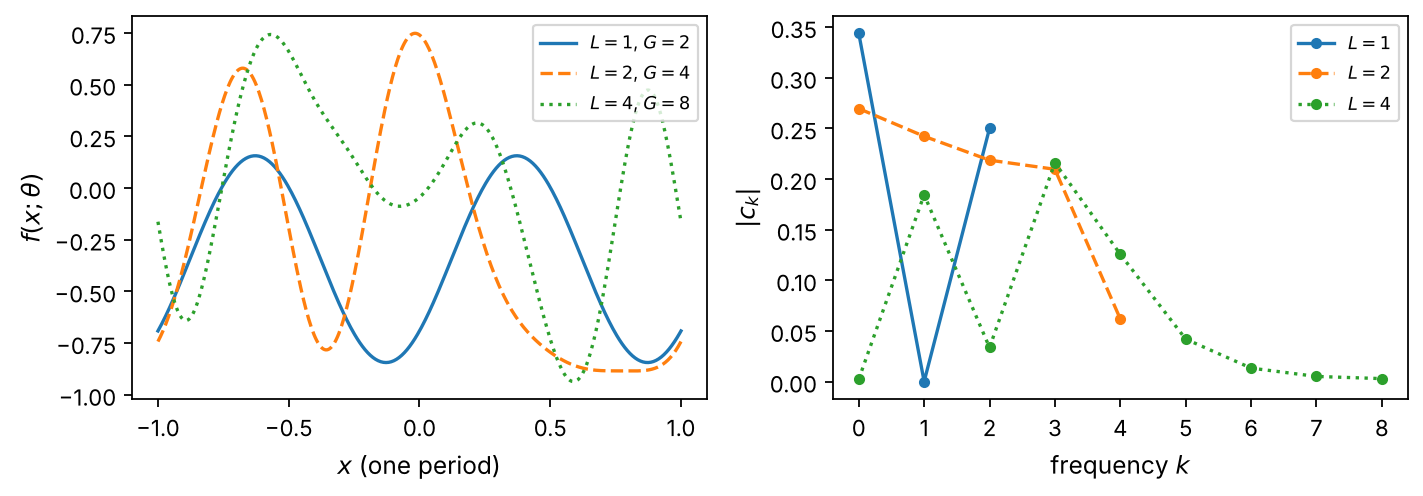

In [6]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter4/qnn.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter4').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


In [7]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter4/training.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter4').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


regressor with 10 parameters: loss 0.572 -> 4.17e-02


single qubit R_y(theta)|0>: F = 1.000000

Table 4-qfirank: the QFI matrix of two-qubit circuits, averaged over 8 inputs
                                     circuit    P  rank F   zero output gradients   |F_exact - F_shift|
                            Y rotations, L=1    2       2                       0               2.2e-16
                            Y rotations, L=2    4       4                       0               3.3e-16
                          Y+Z rotations, L=2    8       8                       2               2.2e-16
     Y rotations, L=2, no re-upload, no CNOT    4       2                       2               2.2e-16


                 Y+Z rotations, L=2, no CNOT    8       8                       5               3.3e-16

transverse-field Ising chain, n=4, h=1.0: E_0 = -4.758770; ansatz with 12 parameters


        gd (eta=0.2): E - E_0 = 1.6880 -> 2.68e-03 after 100 steps  (2.8 s)


      adam (eta=0.1): E - E_0 = 1.6880 -> 3.25e-04 after 100 steps  (3.2 s)


   natural (eta=0.2): E - E_0 = 1.6880 -> 1.00e-07 after 100 steps  (2.9 s)
  eigenvalues of F at the start: min 0.002, max 2.918


figure natgrad written


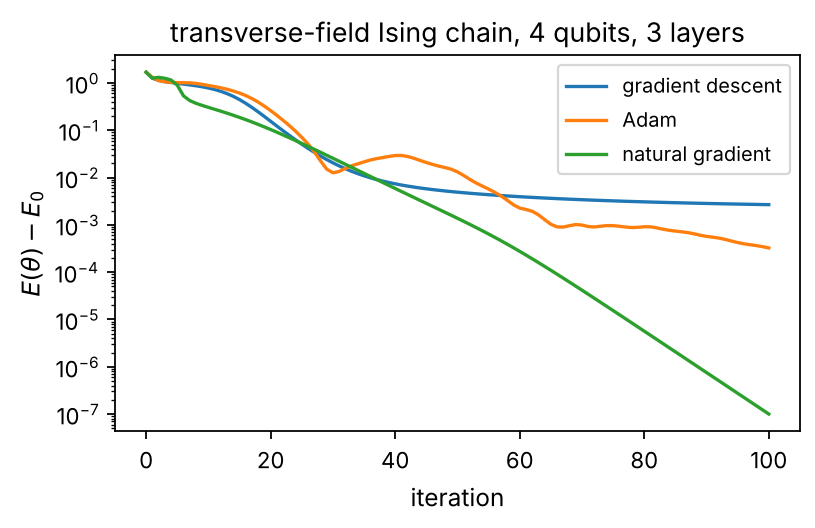

In [8]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter4/qfi.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter4').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


Table 4-barren: Var[dC/dtheta_1] over 200 random parameter sets, depth L = n
  n       local O_L      global O_G      2^-n      4^-n


  2        2.44e-02        3.24e-02   2.5e-01   6.2e-02


  3        9.22e-03        8.66e-03   1.2e-01   1.6e-02


  4        2.80e-03        1.92e-03   6.2e-02   3.9e-03


  5        1.20e-03        3.47e-04   3.1e-02   9.8e-04


...

  L =  6: local 5.02e-04  global 1.28e-04


  L =  8: local 4.04e-04  global 1.61e-04


  L = 12: local 3.57e-04  global 1.17e-04


  L = 16: local 2.97e-04  global 1.37e-04


figure barren written (62 s)


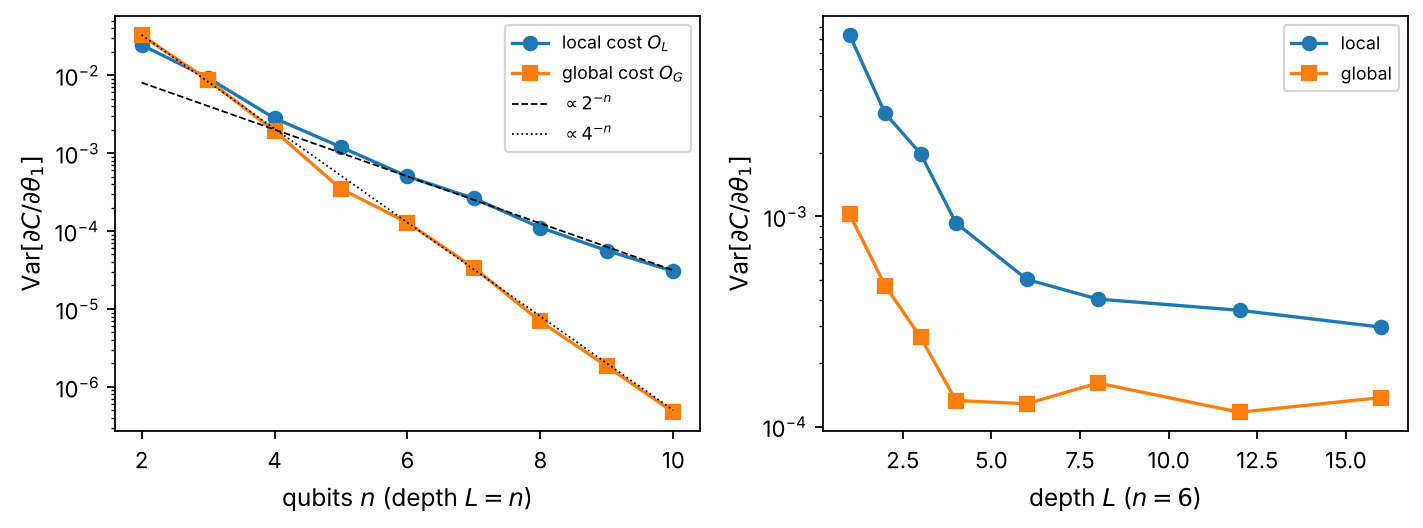

In [9]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter4/barren.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter4').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


Table 4-regression: mean squared error on the test set (original units)
                 model  parameters   train MSE   test MSE    time


         QNN, n=2, L=1           6      7.6723     9.0712    0.5s


         QNN, n=2, L=2          10      0.0548     0.0607    1.0s


         QNN, n=2, L=4          18      0.0285     0.0238    2.5s


         QNN, n=2, L=6          26      0.0256     0.0262    4.8s


         MLP 1-16-16-1         321      0.0242     0.0219    0.5s
           noise floor                             0.0225


figure regression written


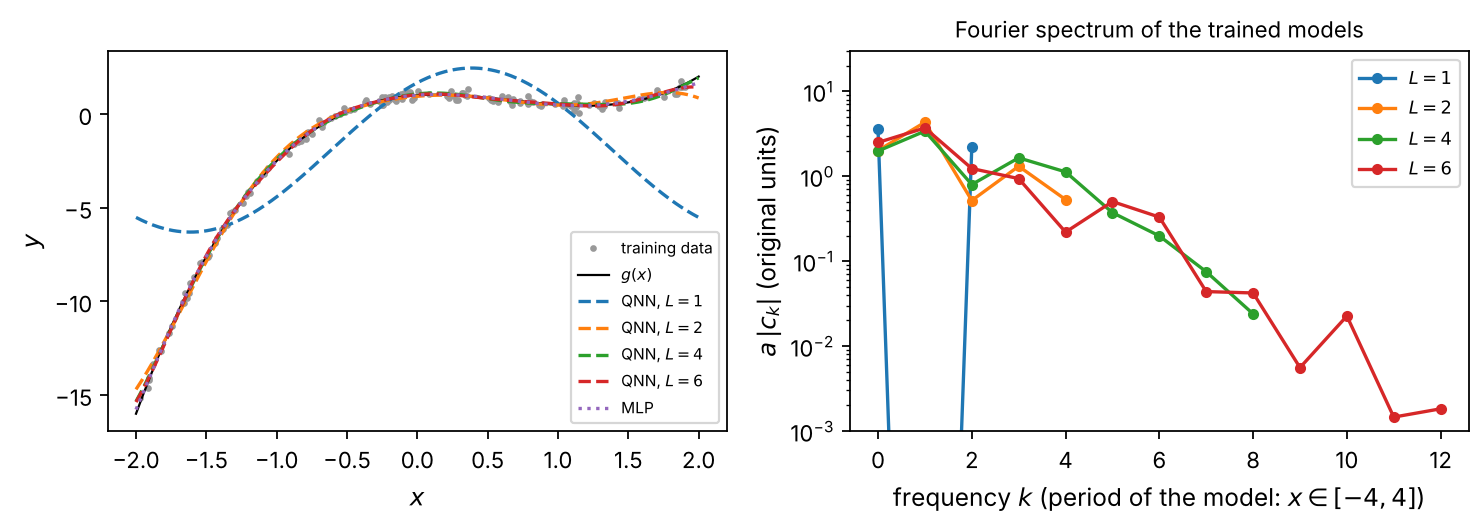

In [10]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter4/regression.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter4').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


Table 4-classifier: training / test accuracy, 70/30 split, 300 Adam steps
data set                         RBF SVM  angle QSVM   QNN L=1 (6)  QNN L=3 (14)


two moons                     0.96/0.97    0.89/0.77      0.87/0.80      0.96/0.97  


two circles                   1.00/1.00    1.00/1.00      1.00/1.00      1.00/1.00  


XOR                           1.00/1.00    1.00/1.00      1.00/1.00      1.00/1.00  


Iris (versicolor/virginica)   0.97/0.90    0.96/0.90      0.94/0.93      0.99/0.90  
(16 s)


figure classifier written


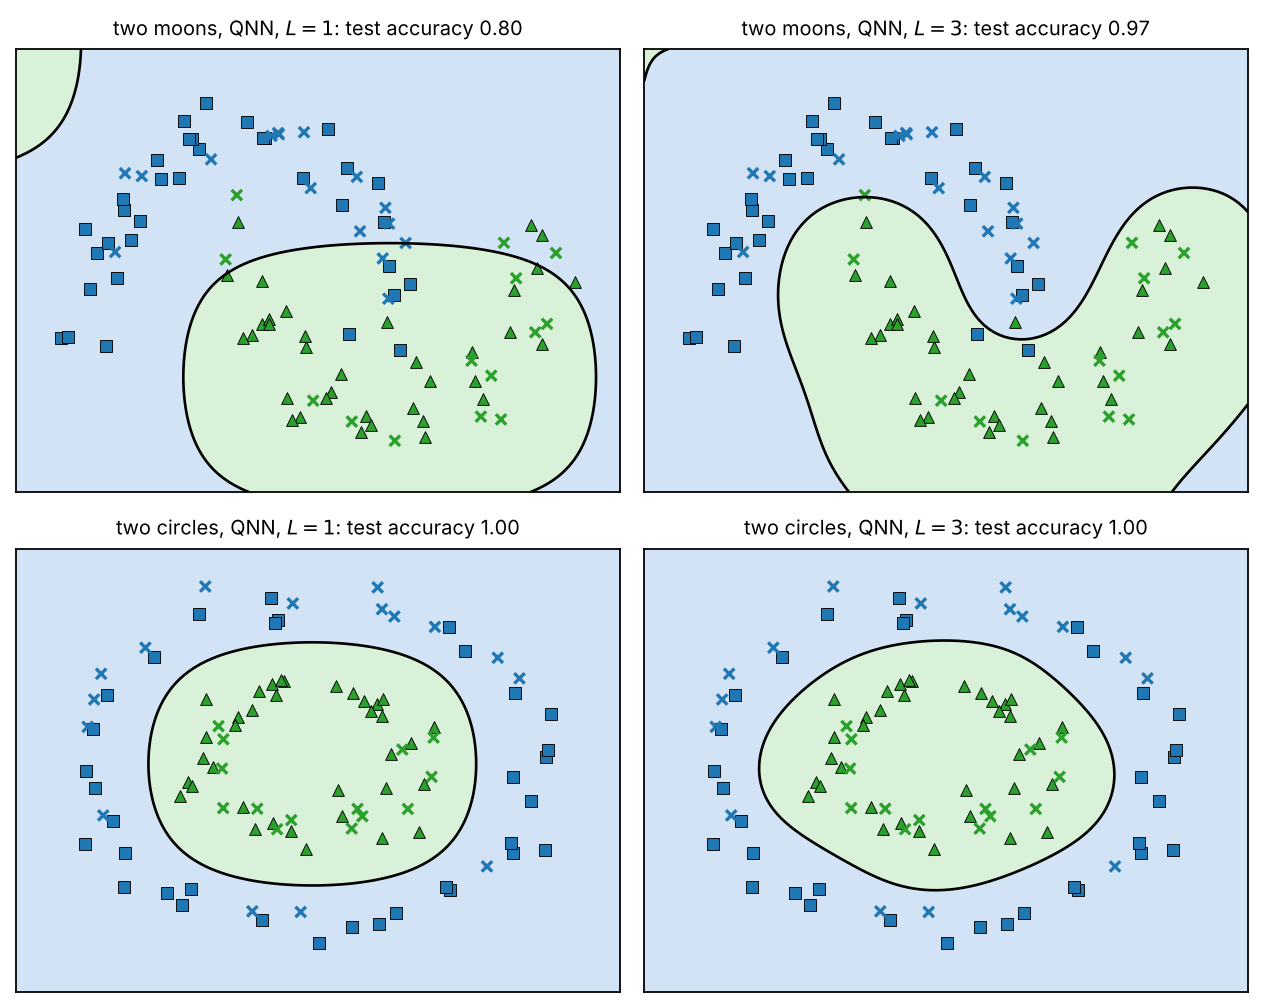

In [11]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter4/classifier.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter4').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


In [12]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter4/portfolio_qnn.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter4').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))



Synthetic data: lambda = 1.0, A = 0.3, K = 2, 18 weights, best of 4 starts
   asset       mu    sigma    score       p
       A    0.120    0.316   -0.894   0.377  
       B    0.100    0.283   -0.793   0.501  <- selected
       C    0.080    0.245   -0.858   0.419  
       D    0.150    0.300   -0.621   0.703  <- selected
  soft cost after training -0.09117; hard portfolio B+D with cost -0.06000; best feasible portfolio B+D with cost -0.06000



S&P data: lambda = 2.0, A = 0.3, K = 2, 18 weights, best of 4 starts
   asset       mu    sigma    score       p
    AAPL    0.309    0.308   -0.254   0.281  
    MSFT    0.246    0.244   +1.000   0.995  <- selected
    AMZN    0.263    0.307   -1.000   0.009  
    GOOG    0.307    0.292   +0.118   0.715  <- selected
  soft cost after training -0.00041; hard portfolio MSFT+GOOG with cost +0.00337; best feasible portfolio MSFT+GOOG with cost +0.00337
(4.2 s)


In [13]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter4/qpinn.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter4').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


Table 4-derivatives: derivatives of the circuit output by the shift rules
               circuit    derivative   general rule  per-gate rule   finite diff.               evaluations
        n=2, L=1 (G=2)         du/dx       2.938503       2.938503       2.938502      4 (general)     4 (gates)
        n=2, L=1 (G=2)       d2u/dx2       6.981992       6.981992       6.981992      5 (general)    14 (gates)
        n=2, L=3 (G=6)         du/dx       0.720406       0.720406       0.720406     12 (general)    12 (gates)
        n=2, L=3 (G=6)       d2u/dx2      27.833288      27.833288      27.833288     13 (general)   138 (gates)
        n=3, L=2 (G=6)         du/dx       3.804347       3.804347       3.804346     12 (general)    12 (gates)
        n=3, L=2 (G=6)       d2u/dx2     -29.664718     -29.664718     -29.664716     13 (general)   138 (gates)
two-variable derivatives (x on two qubits, t on one) verified
gradient of the residual loss: max |shift rule - finite difference| = 1.6e-07


Table 4-poisson: strong-form Q-PINN, 2 qubits, 20 collocation points, BFGS (best of 3 starts)
layers  params  iterations  final loss   L2 error  max error  evaluations/gradient    time


     1       4           4     1.6e+02    1.6e-01    2.5e-01                   800    0.1s


     2       8          63     7.6e-17    8.8e-10    1.2e-09                  2880    1.3s


     3      12         108     3.7e-01    1.2e-02    1.8e-02                  6240    5.3s


Ritz form, L=2: energy -2.46752 (exact -2.46740; midpoint rule on the exact solution -2.46740), L2 error 3.3e-03, 50 iterations (0.6 s)
single layer, random parameters: |c_k| for k = 0..2: [0.4999 0.     0.25  ]


figure poisson written


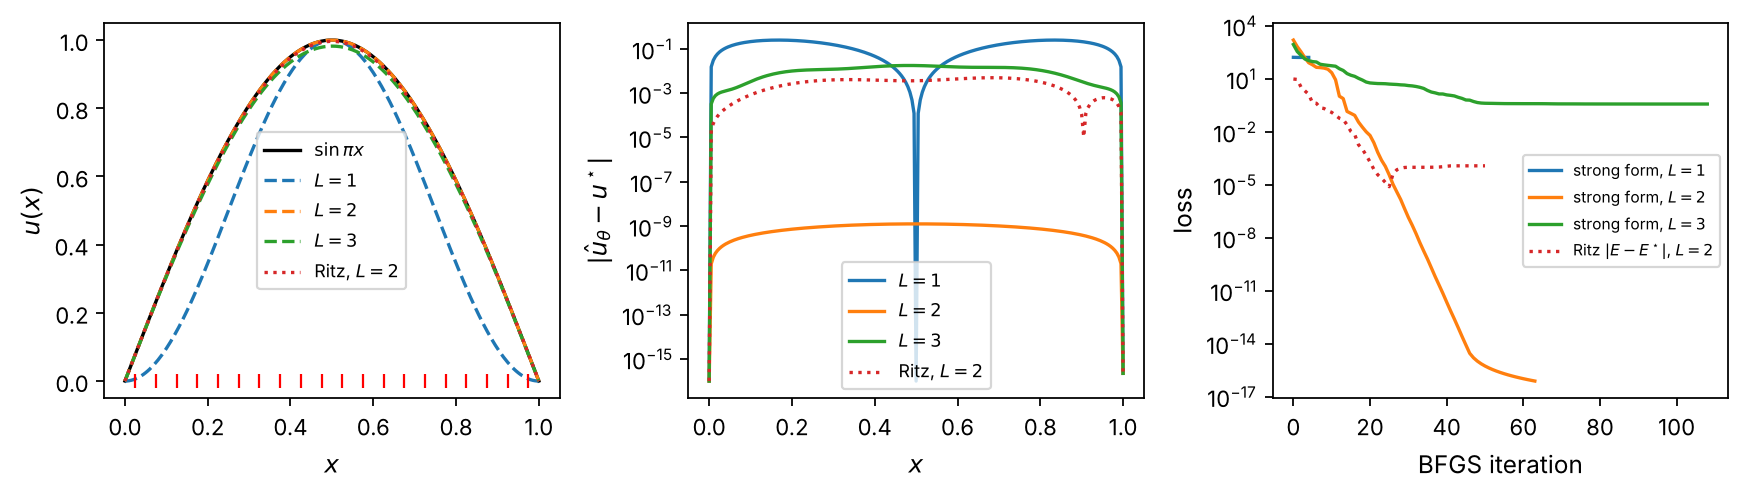

In [14]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter4/poisson.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter4').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


harmonic oscillator, omega = 2.0, 2 qubits, L = 2: final loss 4.5e-07 after 101 BFGS iterations, L2 error 4.6e-06, max error 8.4e-06, u_hat(0) = 0.0e+00, u_hat'(0) = 1.000000 (2.5 s)


wave equation, 2 qubits, L = 1 (4 parameters, 64 collocation points): final loss 1.4e-23 after 14 iterations, L2 error 8.6e-14, max error 2.3e-13 on a 41 x 41 grid (2.5 s)


wave equation, 2 qubits, L = 2 (8 parameters, 64 collocation points): final loss 8.1e+00 after 64 iterations, L2 error 1.3e-01, max error 4.0e-01 on a 41 x 41 grid (25.2 s)
single layer, two qubits: f = cos(phi_0 + theta_0) cos(phi_1 + theta_1), max deviation 5.6e-16


figure timedependent written


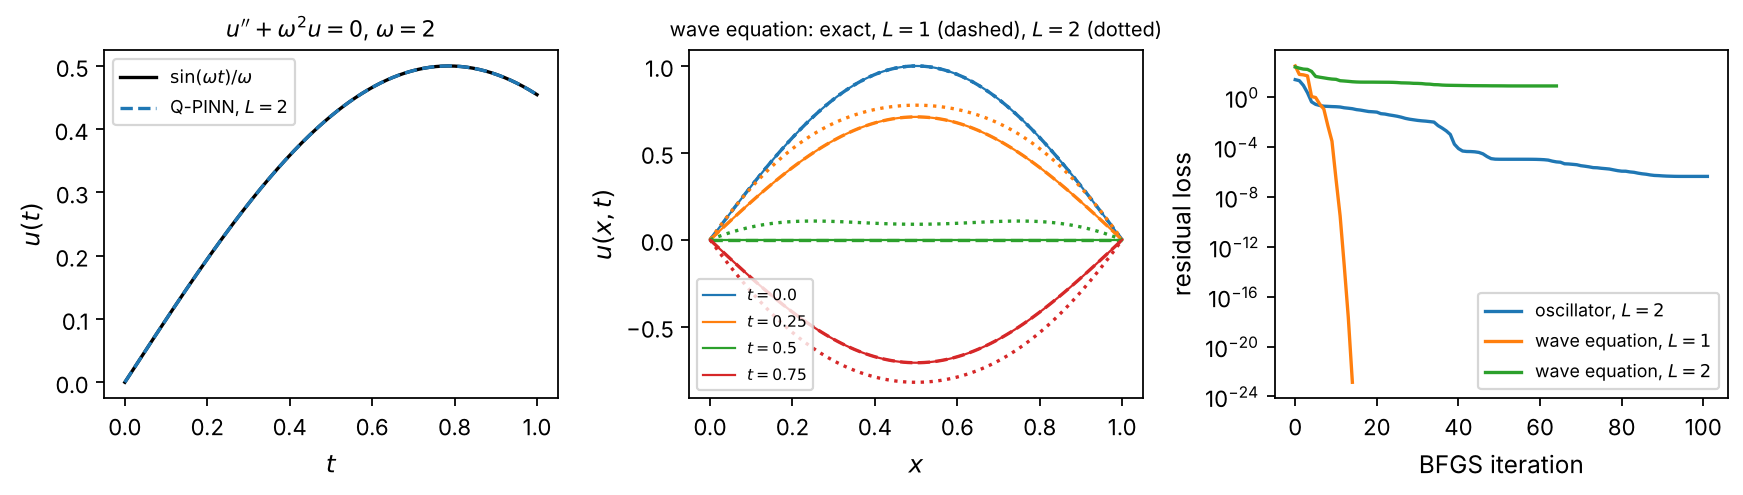

In [15]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter4/timedependent.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter4').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))
